In [ ]:
# Load the LLPSDB_v2_model_dataset.csv file first to proceed in notebook

Total samples: 20,719

Label counts:
Label
0     9059
1    11660
Name: count, dtype: int64

Label percentages:
Label
0    43.72
1    56.28
Name: count, dtype: float64


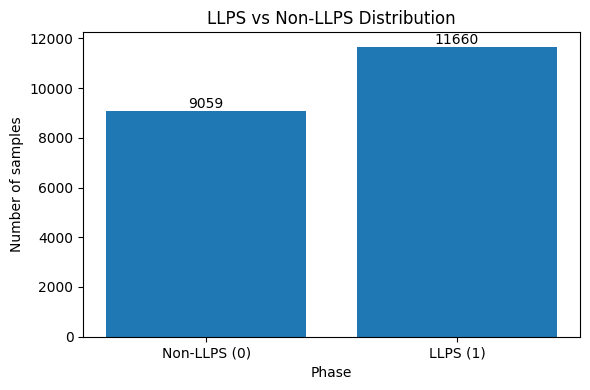

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt


df = pd.read_csv("LLPSDB_v2_model_dataset.csv")

label_counts = df["Label"].value_counts().sort_index()
label_percent = (label_counts / len(df)) * 100

print(f"Total samples: {len(df):,}")

print("\nLabel counts:")
print(label_counts)

print("\nLabel percentages:")
print(label_percent.round(2))


plt.figure(figsize=(6, 4))

labels = ["Non-LLPS (0)", "LLPS (1)"]
counts = [
    label_counts.get(0, 0),
    label_counts.get(1, 0),
]

bars = plt.bar(labels, counts)

plt.xlabel("Phase")
plt.ylabel("Number of samples")
plt.title("LLPS vs Non-LLPS Distribution")

for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height,
        f"{int(height)}",
        ha="center",
        va="bottom",
    )

plt.tight_layout()
plt.show()

Number of numerical features: 56


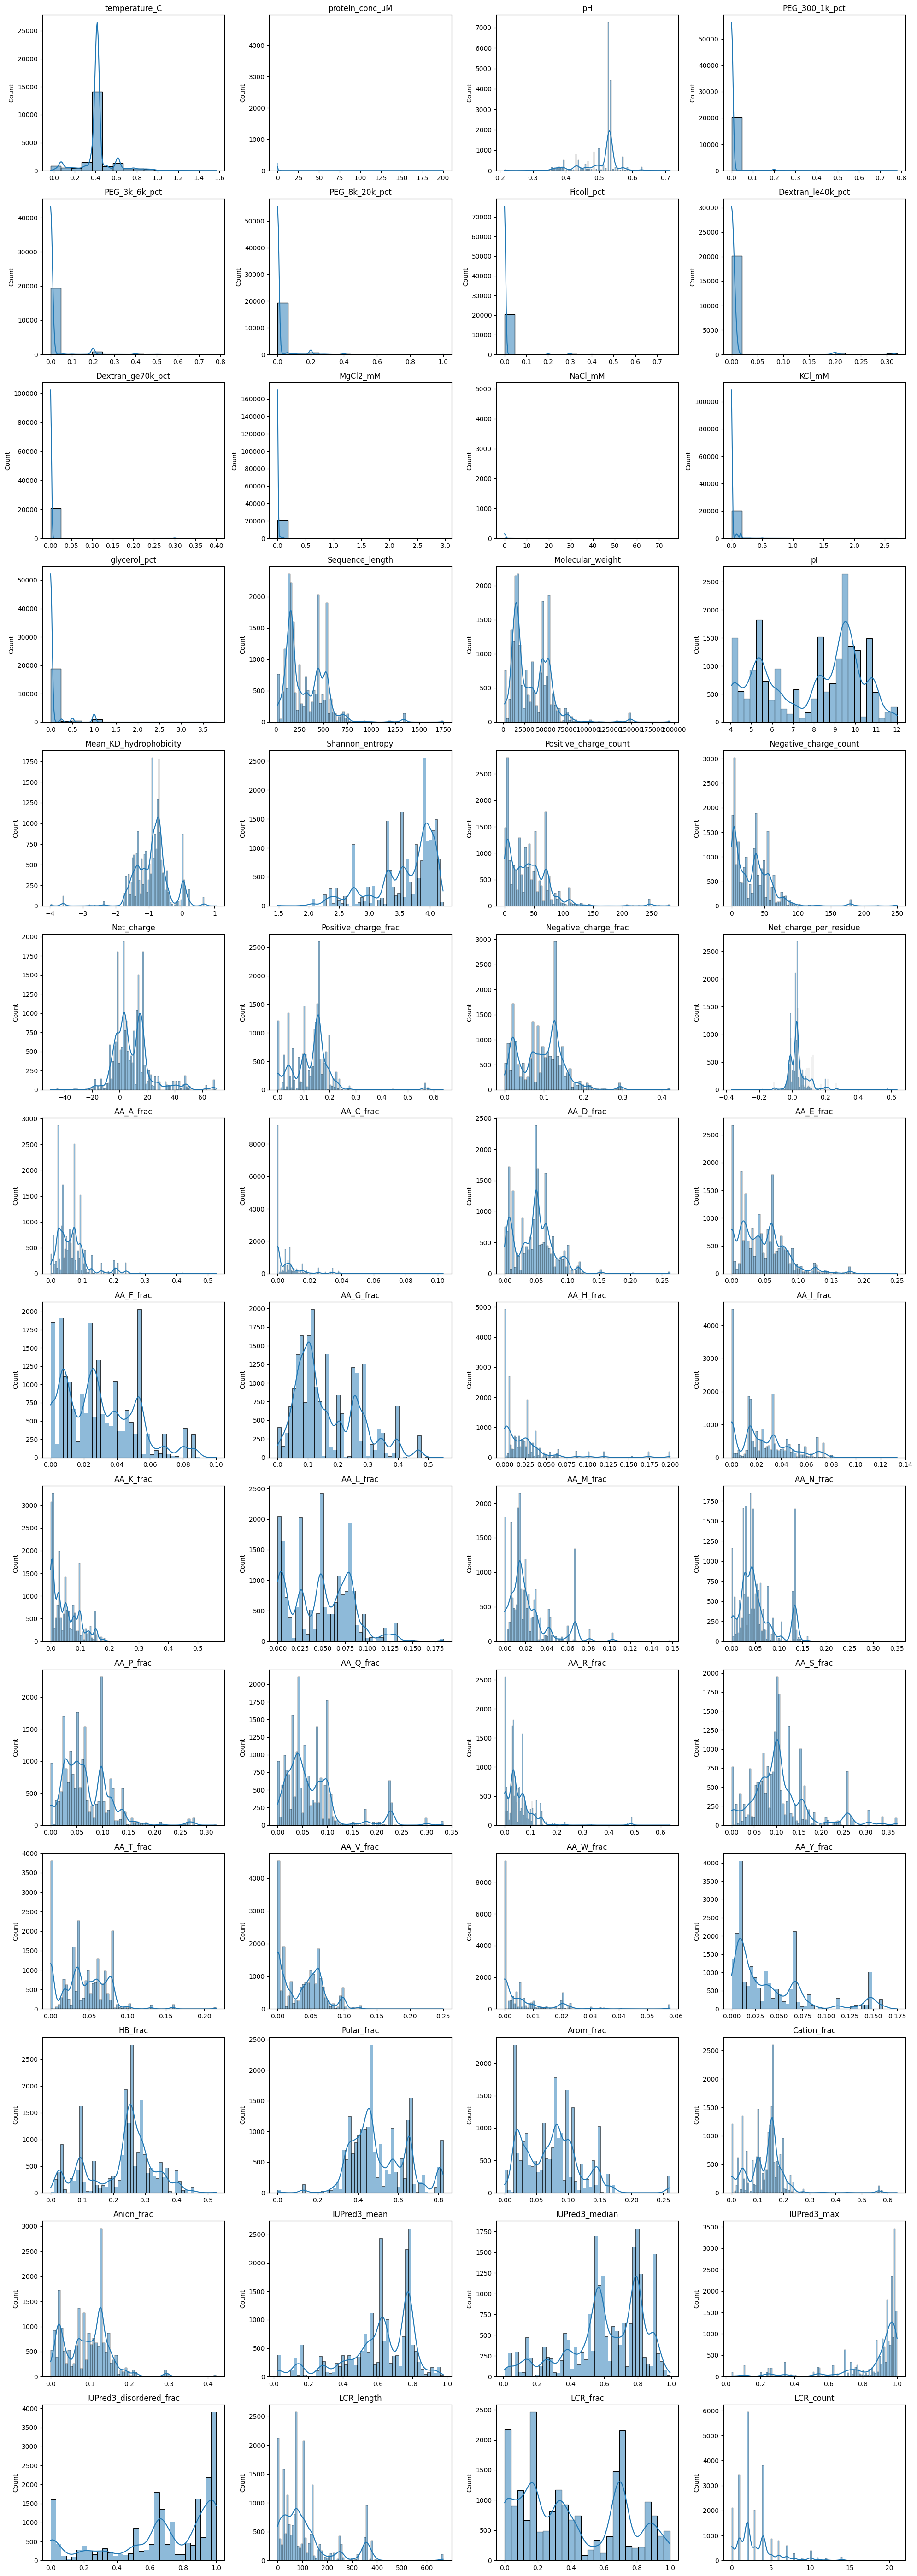

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


numeric_features = df.select_dtypes(include=np.number).columns.tolist()
numeric_features.remove("Label")

print(f"Number of numerical features: {len(numeric_features)}")


n_cols = 4
n_rows = int(np.ceil(len(numeric_features) / n_cols))

fig, axes = plt.subplots(
    n_rows,
    n_cols,
    figsize=(20, n_rows * 4),
)

axes = np.asarray(axes).flatten()

for ax, feature in zip(axes, numeric_features):
    sns.histplot(
        df[feature],
        kde=True,
        ax=ax,
    )

    ax.set_title(feature)
    ax.set_xlabel("")
    ax.set_ylabel("Count")


for ax in axes[len(numeric_features):]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()

In [ ]:


summary = df[numeric_features].describe().T

summary["missing"] = df[numeric_features].isna().sum()
summary["unique"] = df[numeric_features].nunique()
summary["skewness"] = df[numeric_features].skew()

display(summary)

,count,mean,std,min,25%,50%,75%,max,missing,unique,skewness
temperature_C,20719.0,0.421446,0.148179,-0.033333,0.416667,0.416667,0.416667,1.566667,0,280,0.624282
protein_conc_uM,20719.0,0.255918,2.333113,0.000000,0.007300,0.020000,0.080000,200.000000,0,1032,62.172927
pH,20719.0,0.503135,0.058515,0.214286,0.485714,0.528571,0.535714,0.714286,0,319,-1.280332
PEG_300_1k_pct,20719.0,0.006584,0.050961,0.000000,0.000000,0.000000,0.000000,0.780000,0,71,9.601033
PEG_3k_6k_pct,20719.0,0.014385,0.063553,0.000000,0.000000,0.000000,0.000000,0.780000,0,87,5.648766
PEG_8k_20k_pct,20719.0,0.014712,0.062399,0.000000,0.000000,0.000000,0.000000,1.000000,0,109,6.110510
Ficoll_pct,20719.0,0.004508,0.037367,0.000000,0.000000,0.000000,0.000000,0.760000,0,40,9.488399
Dextran_le40k_pct,20719.0,0.005905,0.038822,0.000000,0.000000,0.000000,0.000000,0.320000,0,26,6.812617
Dextran_ge70k_pct,20719.0,0.000777,0.014722,0.000000,0.000000,0.000000,0.000000,0.400000,0,17,19.629226
MgCl2_mM,20719.0,0.002791,0.063737,0.000000,0.000000,0.000000,0.000000,2.960000,0,19,44.022429


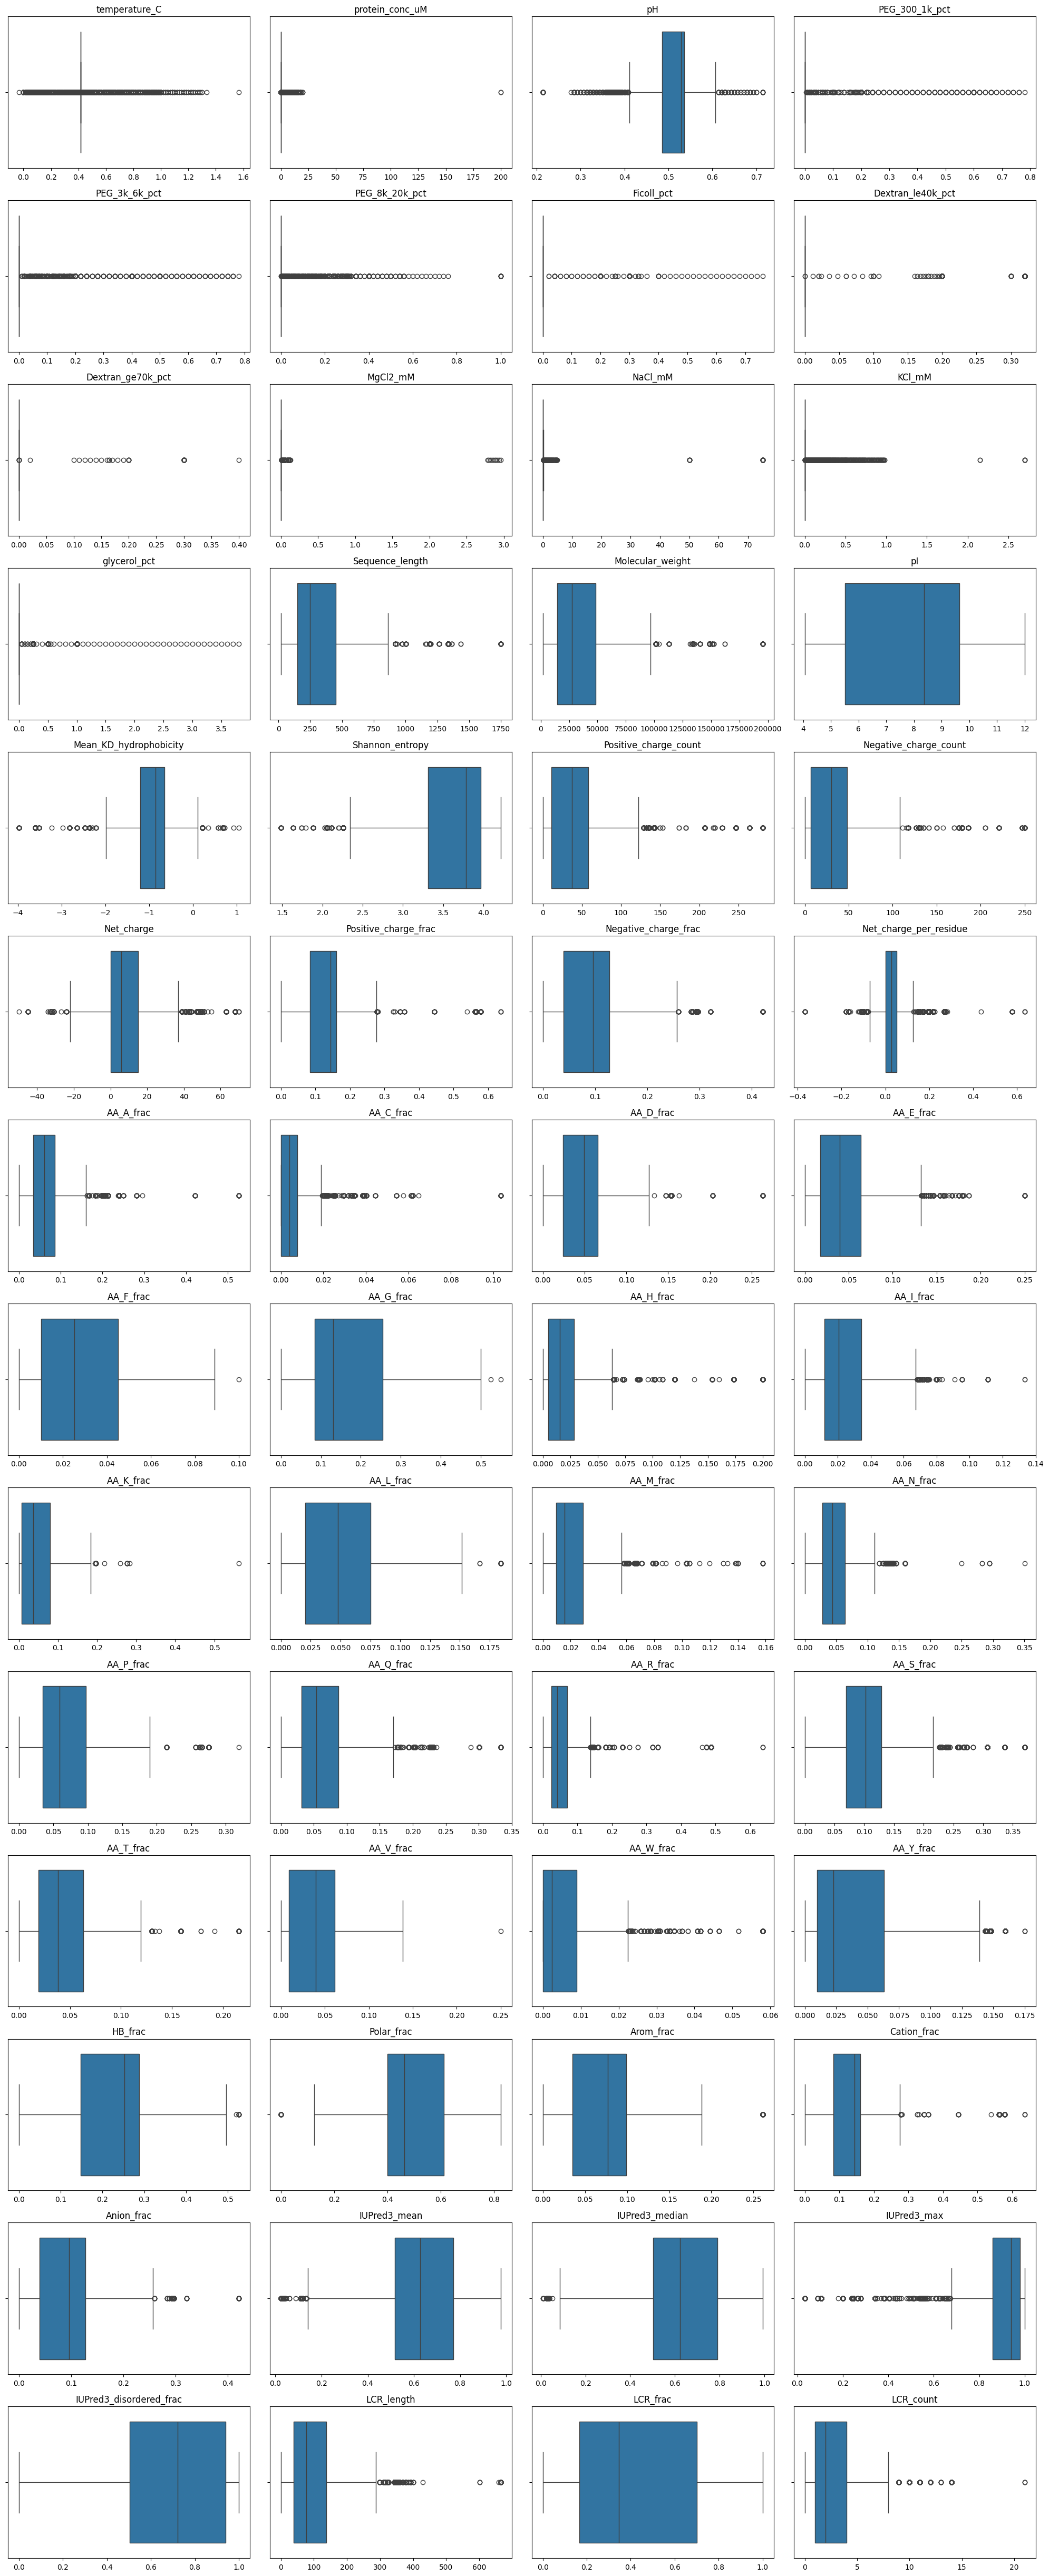

In [ ]:


n_cols = 4
n_rows = int(np.ceil(len(numeric_features) / n_cols))

fig, axes = plt.subplots(
    n_rows,
    n_cols,
    figsize=(20, n_rows * 3.5)
)

axes = axes.flatten()

for i, feature in enumerate(numeric_features):
    sns.boxplot(
        x=df[feature],
        ax=axes[i]
    )

    axes[i].set_title(feature)
    axes[i].set_xlabel("")

for i in range(len(numeric_features), len(axes)):
    axes[i].set_visible(False)

plt.tight_layout()
plt.show()

In [ ]:


skewness = (
    df[numeric_features]
    .skew()
    .abs()
    .sort_values(ascending=False)
)

print("Features with highest absolute skewness:")
display(skewness.to_frame("Absolute Skewness").head(15))

Features with highest absolute skewness:


,Absolute Skewness
protein_conc_uM,62.172927
MgCl2_mM,44.022429
NaCl_mM,24.888496
Dextran_ge70k_pct,19.629226
KCl_mM,12.362112
PEG_300_1k_pct,9.601033
Ficoll_pct,9.488399
Dextran_le40k_pct,6.812617
PEG_8k_20k_pct,6.110510
PEG_3k_6k_pct,5.648766


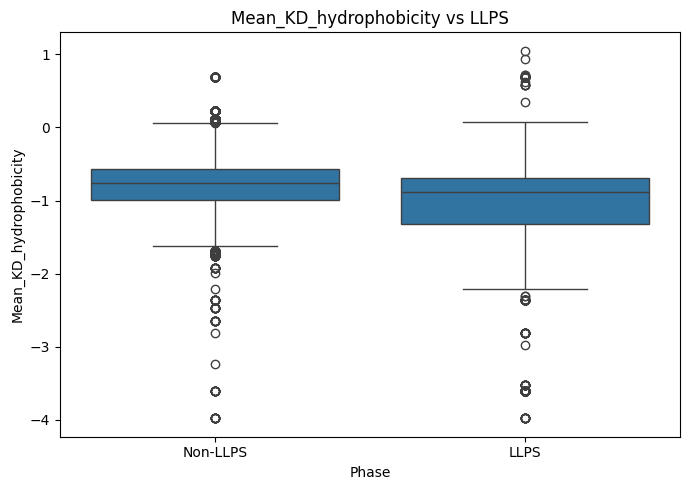

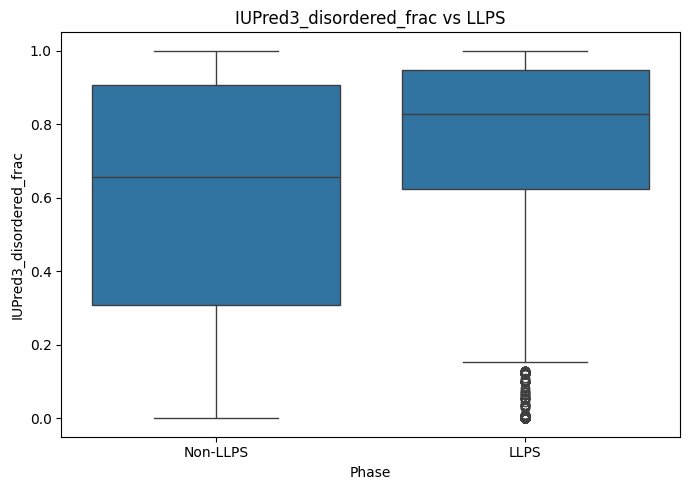

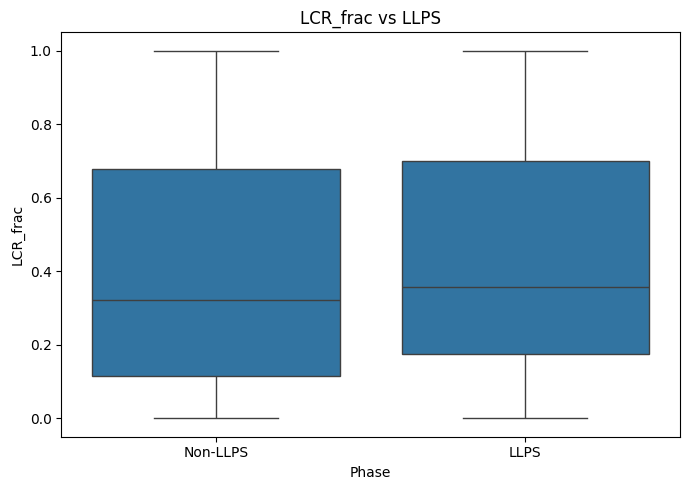

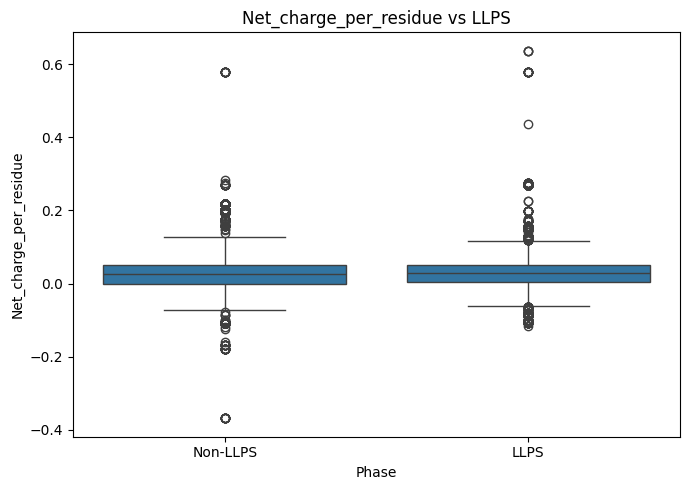

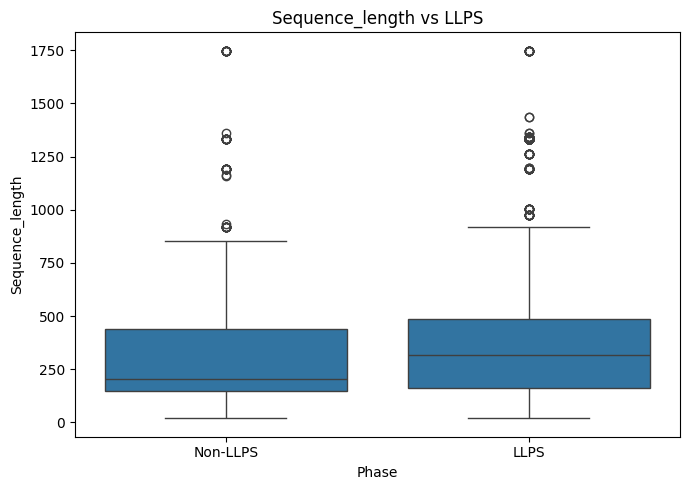

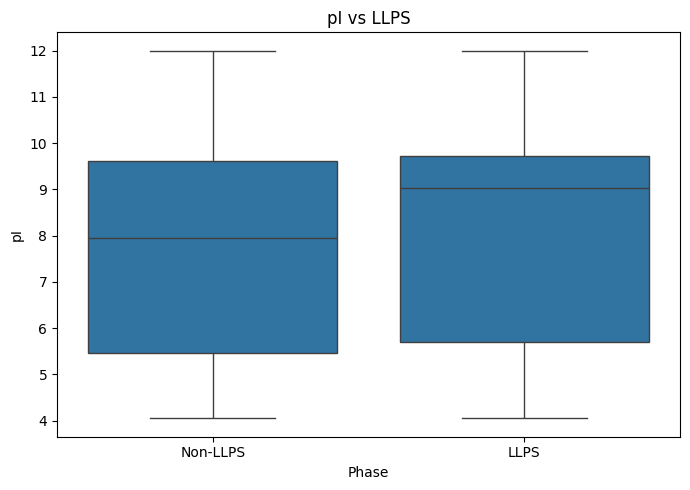

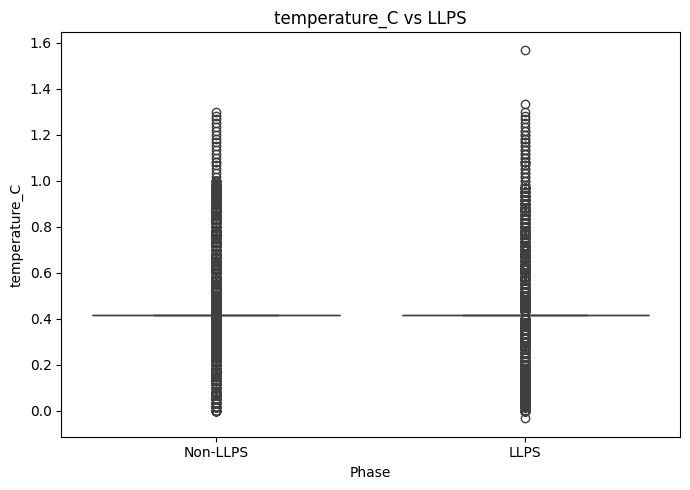

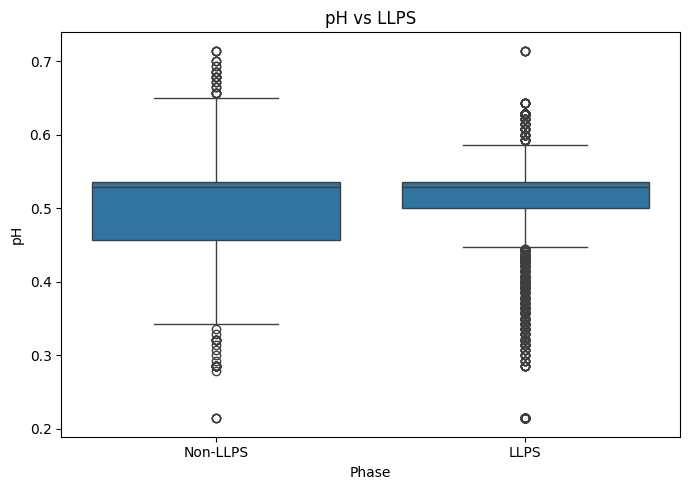

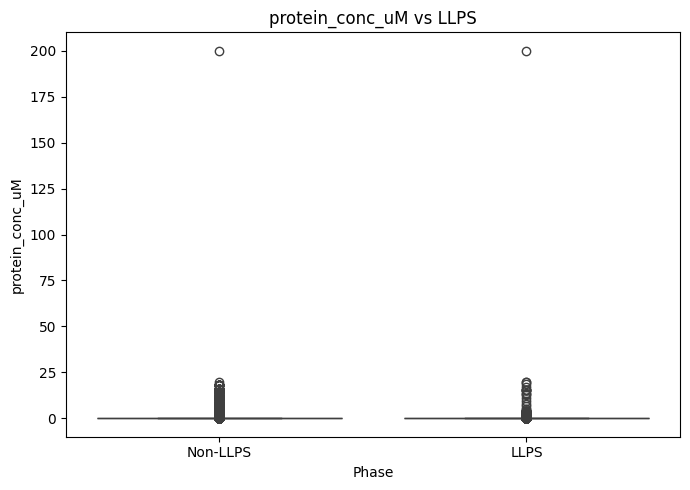

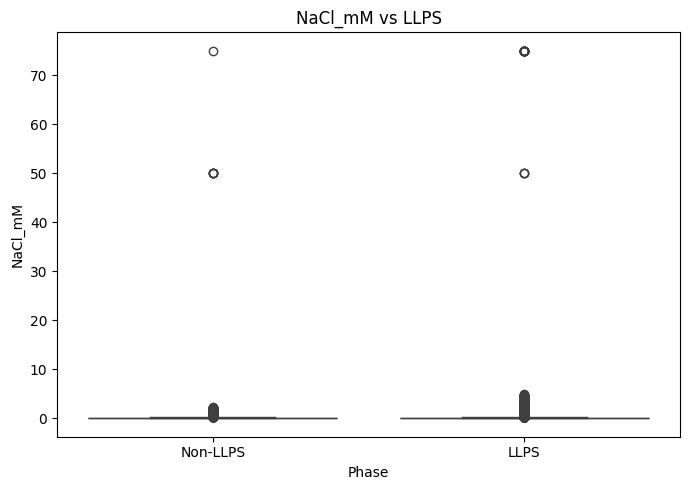

In [ ]:
#feature vs llps

import matplotlib.pyplot as plt
import seaborn as sns

features = [
    "Mean_KD_hydrophobicity",
    "IUPred3_disordered_frac",
    "LCR_frac",
    "Net_charge_per_residue",
    "Sequence_length",
    "pI",
    "temperature_C",
    "pH",
    "protein_conc_uM",
    "NaCl_mM"
]

for feature in features:

    if feature not in df.columns:
        print(f"{feature} not found")
        continue

    plt.figure(figsize=(7, 5))

    sns.boxplot(
        data=df,
        x="Label",
        y=feature
    )

    plt.xticks(
        [0, 1],
        ["Non-LLPS", "LLPS"]
    )

    plt.xlabel("Phase")
    plt.ylabel(feature)
    plt.title(f"{feature} vs LLPS")

    plt.tight_layout()
    plt.show()

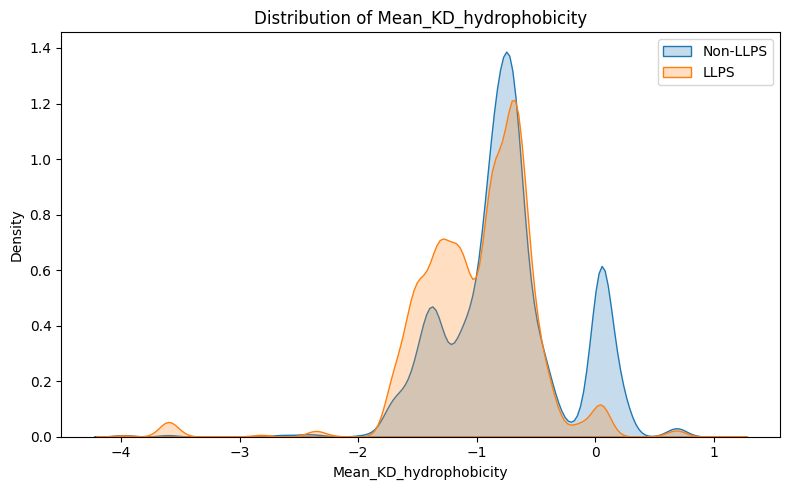

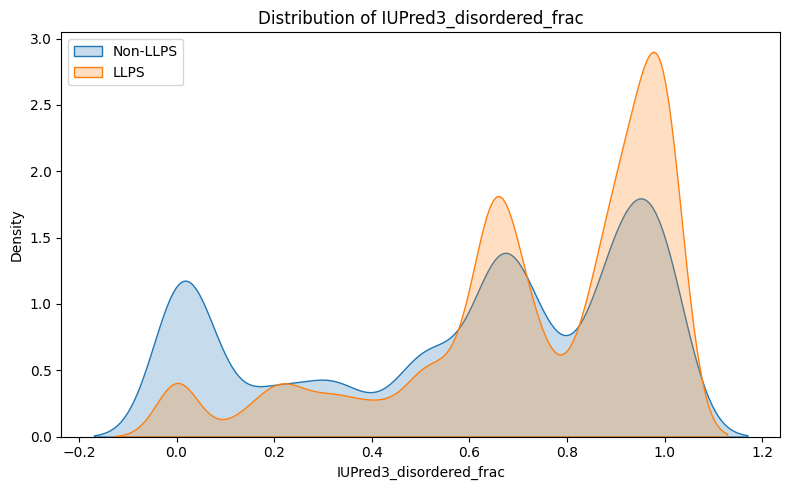

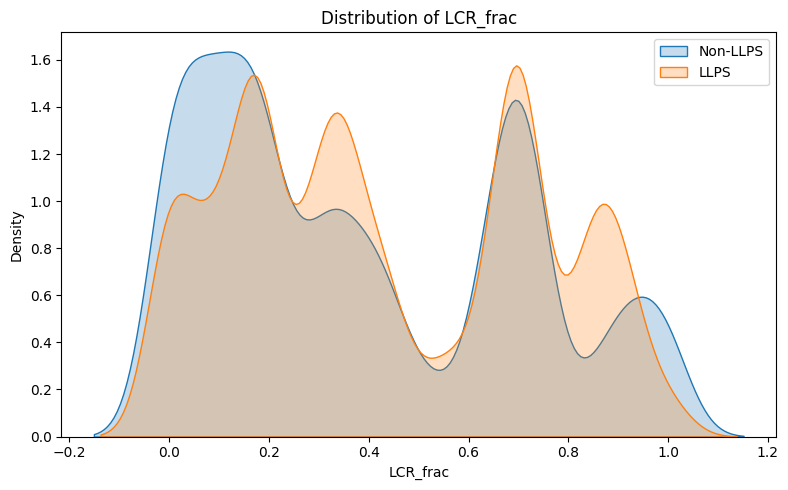

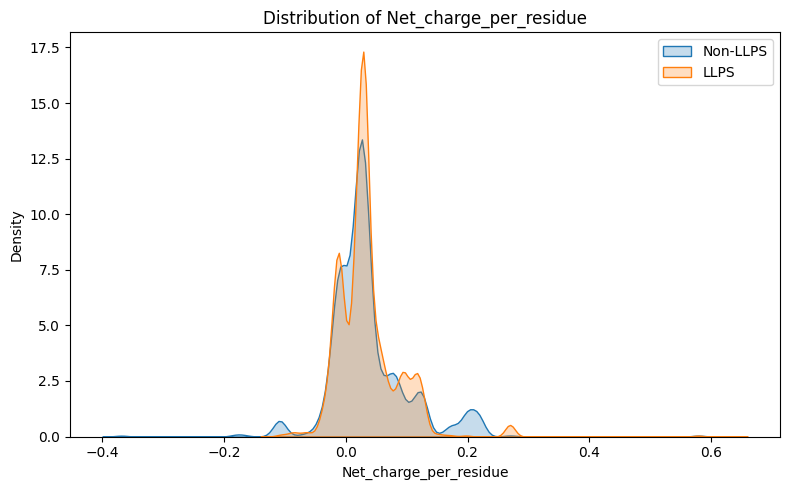

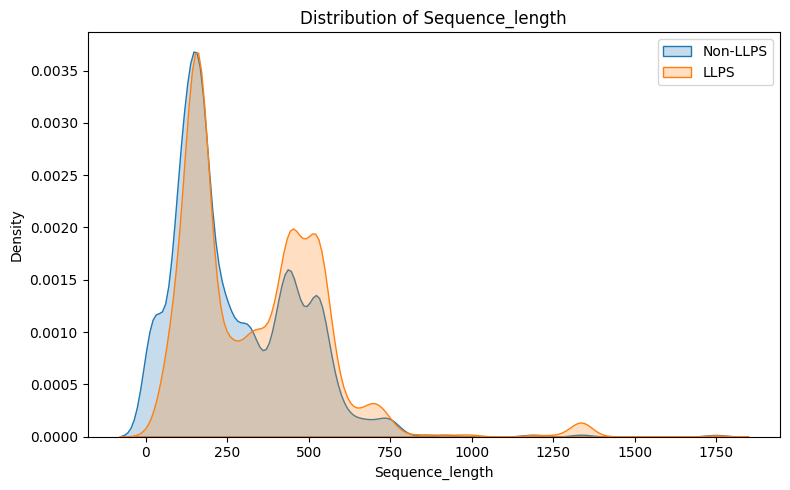

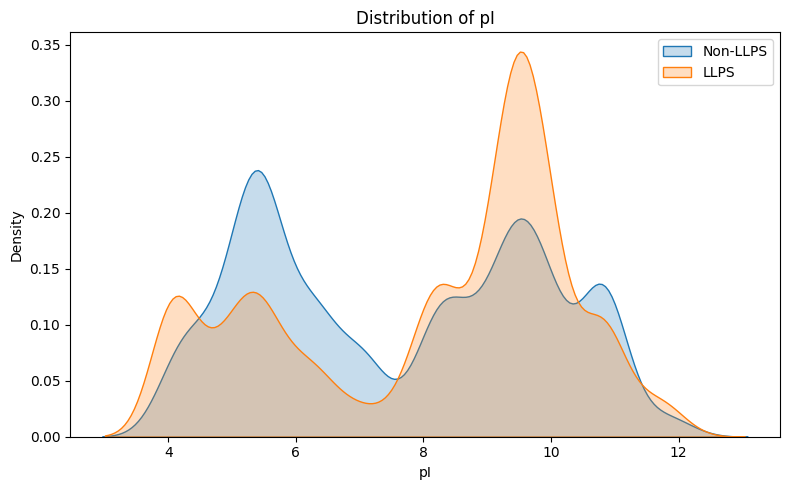

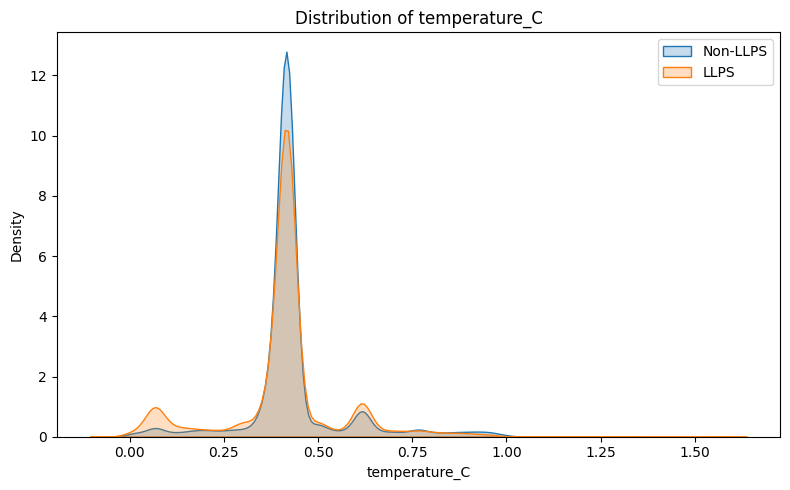

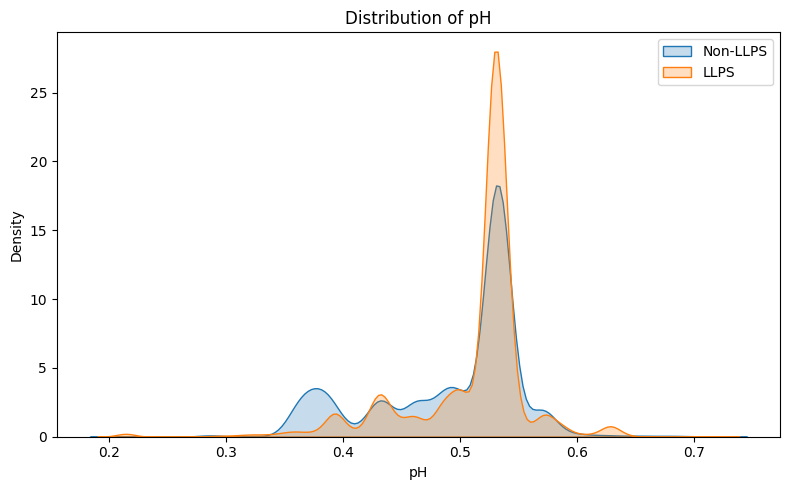

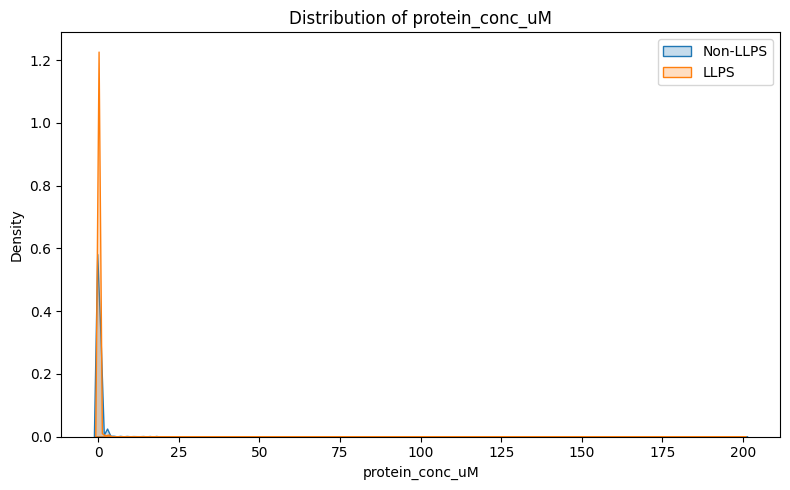

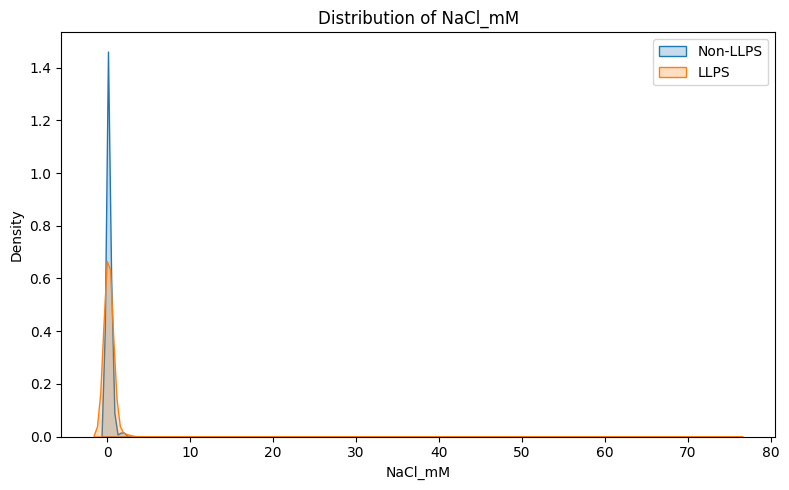

In [ ]:
#llps vs non llps

for feature in features:

    if feature not in df.columns:
        continue

    plt.figure(figsize=(8, 5))

    sns.kdeplot(
        data=df[df["Label"] == 0],
        x=feature,
        fill=True,
        label="Non-LLPS"
    )

    sns.kdeplot(
        data=df[df["Label"] == 1],
        x=feature,
        fill=True,
        label="LLPS"
    )

    plt.xlabel(feature)
    plt.ylabel("Density")
    plt.title(f"Distribution of {feature}")
    plt.legend()

    plt.tight_layout()
    plt.show()

In [ ]:
# ==========================================
#LLPS PROBABILITY vs FEATURE
# ==========================================

def plot_llps_probability(df, feature, bins=10):

    temp = df[[feature, "Label"]].dropna().copy()

    # Divide feature into quantile-based bins
    temp["bin"] = pd.qcut(
        temp[feature],
        q=bins,
        duplicates="drop"
    )

    result = (
        temp.groupby("bin", observed=True)
        .agg(
            feature_mean=(feature, "mean"),
            llps_rate=("Label", "mean"),
            sample_count=("Label", "count")
        )
        .reset_index()
    )

    result["llps_rate"] *= 100

    plt.figure(figsize=(8, 5))

    plt.plot(
        result["feature_mean"],
        result["llps_rate"],
        marker="o"
    )

    plt.xlabel(feature)
    plt.ylabel("LLPS (%)")
    plt.title(f"LLPS Probability vs {feature}")
    plt.grid(alpha=0.3)

    plt.tight_layout()
    plt.show()

    display(result)

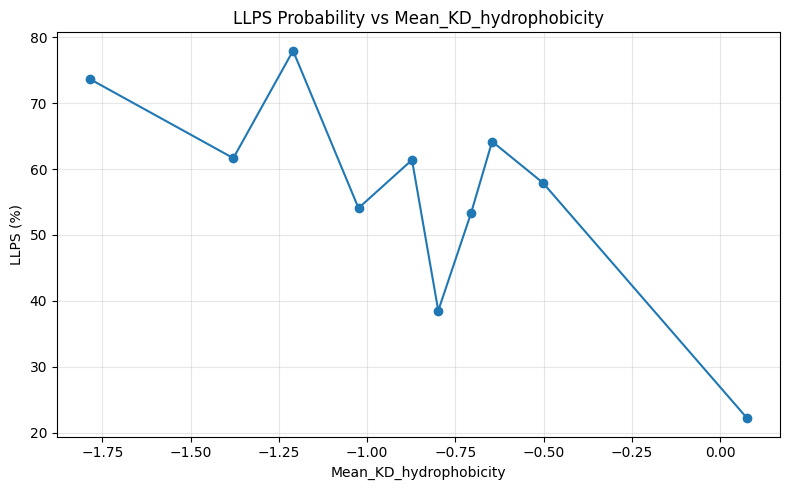

,bin,feature_mean,llps_rate,sample_count
0,"(-3.98, -1.504]",-1.785799,73.661972,2130
1,"(-1.504, -1.319]",-1.379022,61.648250,2172
2,"(-1.319, -1.131]",-1.209778,77.951933,1914
3,"(-1.131, -0.933]",-1.024294,54.071363,2186
4,"(-0.933, -0.857]",-0.872751,61.384152,1994
5,"(-0.857, -0.742]",-0.798290,38.506876,2036
6,"(-0.742, -0.69]",-0.705480,53.297829,2441
7,"(-0.69, -0.606]",-0.645684,64.174813,1739
8,"(-0.606, -0.349]",-0.502184,57.927711,2075
9,"(-0.349, 1.05]",0.076879,22.194882,2032


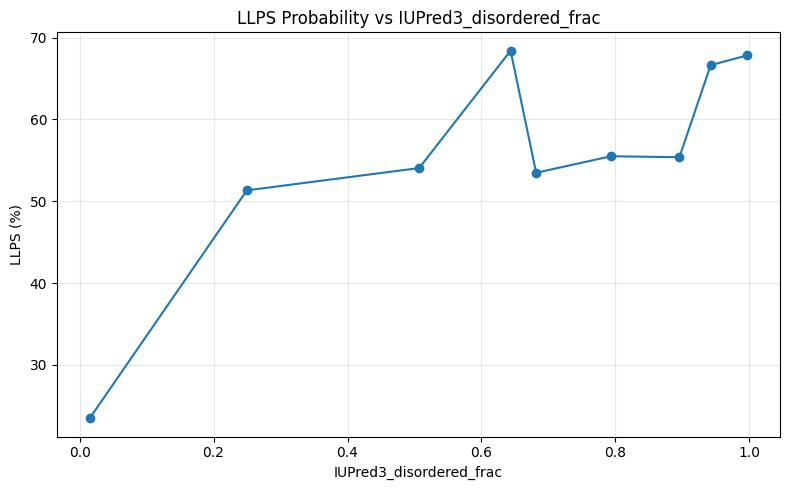

,bin,feature_mean,llps_rate,sample_count
0,"(-0.001, 0.063]",0.015177,23.491479,2171
1,"(0.063, 0.367]",0.249723,51.332328,1989
2,"(0.367, 0.599]",0.506990,54.059217,2094
3,"(0.599, 0.655]",0.643505,68.396447,2139
4,"(0.655, 0.722]",0.681673,53.482587,2010
5,"(0.722, 0.883]",0.793430,55.500982,2036
6,"(0.883, 0.931]",0.895541,55.381697,2109
7,"(0.931, 0.949]",0.942252,66.634051,2044
8,"(0.949, 1.0]",0.996678,67.821662,4127


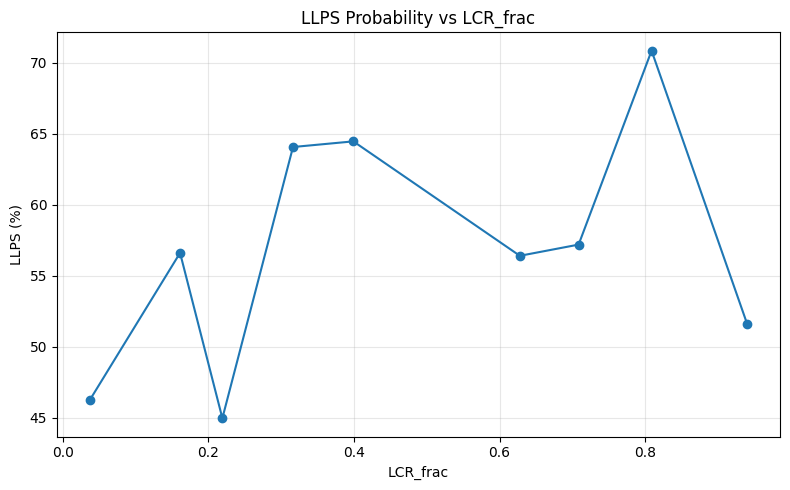

,bin,feature_mean,llps_rate,sample_count
0,"(-0.001, 0.11]",0.036939,46.259653,4144
1,"(0.11, 0.175]",0.160997,56.624826,2868
2,"(0.175, 0.263]",0.219137,44.984568,1296
3,"(0.263, 0.347]",0.316186,64.081435,2063
4,"(0.347, 0.449]",0.399095,64.478936,2255
5,"(0.449, 0.679]",0.627897,56.421134,2593
6,"(0.679, 0.716]",0.708615,57.209544,1928
7,"(0.716, 0.865]",0.808876,70.863112,1819
8,"(0.865, 1.0]",0.940163,51.625784,1753


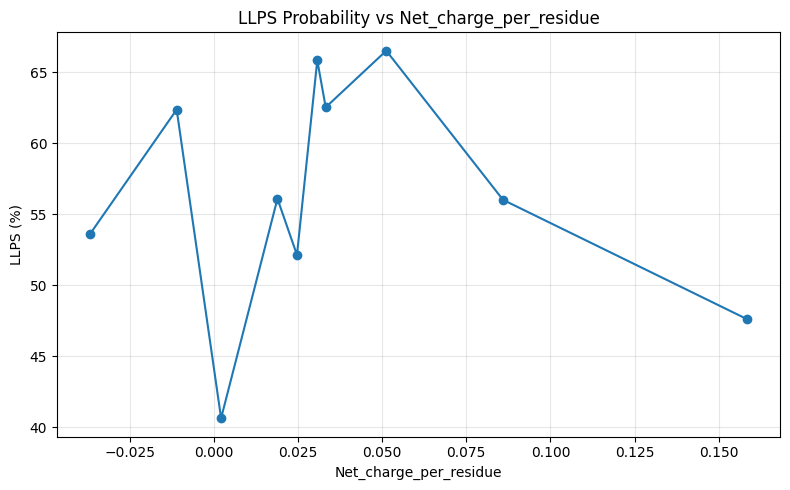

,bin,feature_mean,llps_rate,sample_count
0,"(-0.369, -0.0154]",-0.036844,53.579176,2305
1,"(-0.0154, -0.00658]",-0.011031,62.371413,1847
2,"(-0.00658, 0.0118]",0.002167,40.630885,2124
3,"(0.0118, 0.0203]",0.018906,56.093108,2191
4,"(0.0203, 0.0287]",0.024700,52.131980,1970
5,"(0.0287, 0.0317]",0.030734,65.837544,2573
6,"(0.0317, 0.0363]",0.033241,62.532300,1548
7,"(0.0363, 0.0649]",0.051229,66.518738,2028
8,"(0.0649, 0.109]",0.085907,56.013416,2087
9,"(0.109, 0.636]",0.158420,47.605083,2046


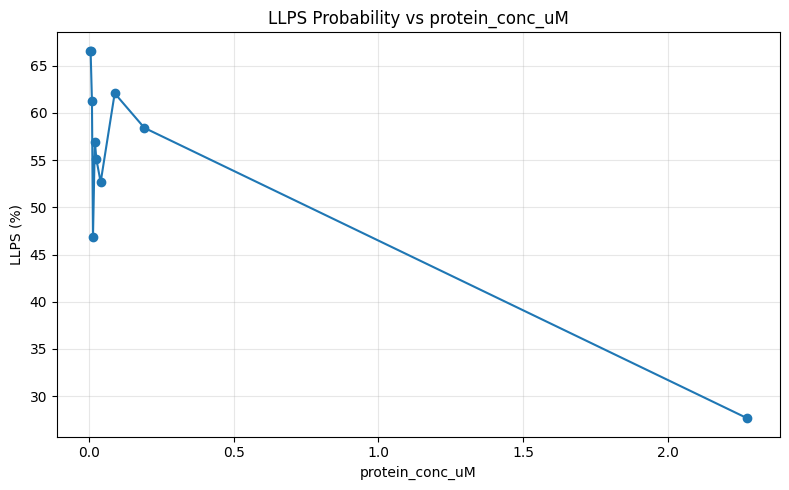

,bin,feature_mean,llps_rate,sample_count
0,"(-0.001, 0.00213]",0.001349,66.586654,2083
1,"(0.00213, 0.005]",0.004283,66.539924,2630
2,"(0.005, 0.01]",0.008879,61.244980,2490
3,"(0.01, 0.0147]",0.012428,46.820276,1085
4,"(0.0147, 0.02]",0.018906,56.965425,2979
5,"(0.02, 0.025]",0.024282,55.078684,1398
6,"(0.025, 0.05]",0.038998,52.660707,2349
7,"(0.05, 0.1]",0.087544,62.076161,1917
8,"(0.1, 0.3]",0.190174,58.417508,1782
9,"(0.3, 200.0]",2.275233,27.666999,2006


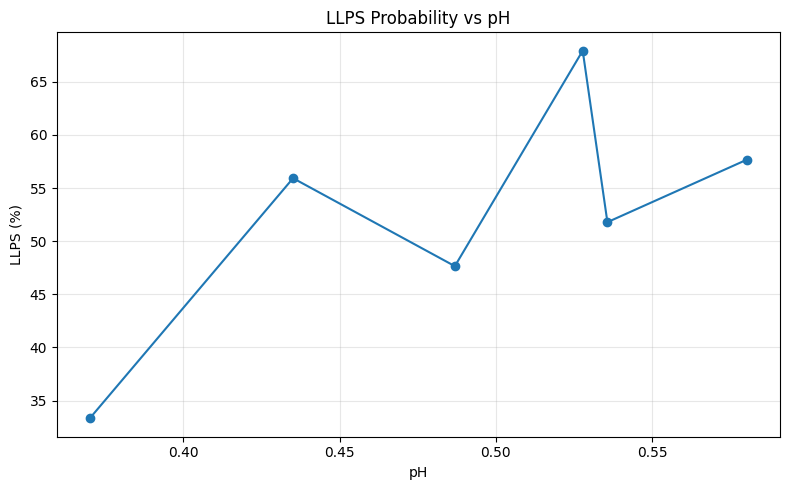

,bin,feature_mean,llps_rate,sample_count
0,"(0.213, 0.4]",0.370031,33.333333,2073
1,"(0.4, 0.457]",0.435102,55.928949,2083
2,"(0.457, 0.5]",0.486883,47.653430,2770
3,"(0.5, 0.529]",0.527807,67.926243,7701
4,"(0.529, 0.536]",0.535714,51.793368,4433
5,"(0.536, 0.714]",0.580434,57.685353,1659


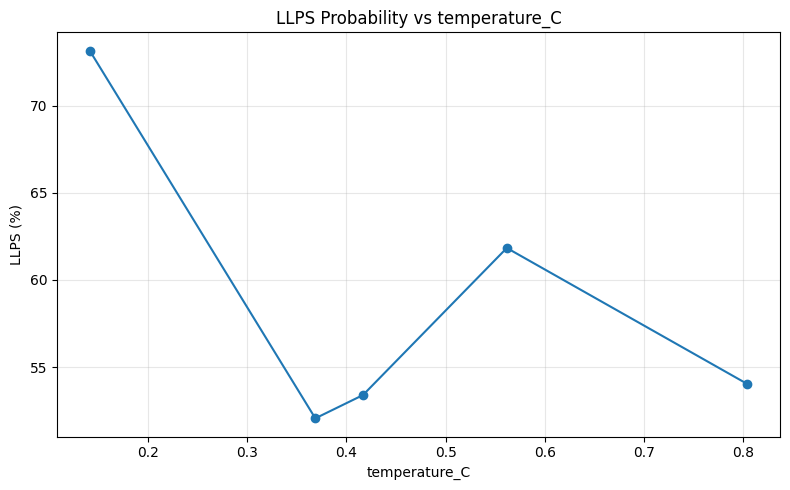

,bin,feature_mean,llps_rate,sample_count
0,"(-0.034300000000000004, 0.3]",0.141367,73.151927,2205
1,"(0.3, 0.4]",0.368661,52.062374,1988
2,"(0.4, 0.417]",0.416662,53.397836,13126
3,"(0.417, 0.617]",0.561609,61.835294,2125
4,"(0.617, 1.567]",0.803758,54.039216,1275


In [ ]:
plot_llps_probability(df, "Mean_KD_hydrophobicity")
plot_llps_probability(df, "IUPred3_disordered_frac")
plot_llps_probability(df, "LCR_frac")
plot_llps_probability(df, "Net_charge_per_residue")
plot_llps_probability(df, "protein_conc_uM")
plot_llps_probability(df, "pH")
plot_llps_probability(df, "temperature_C")

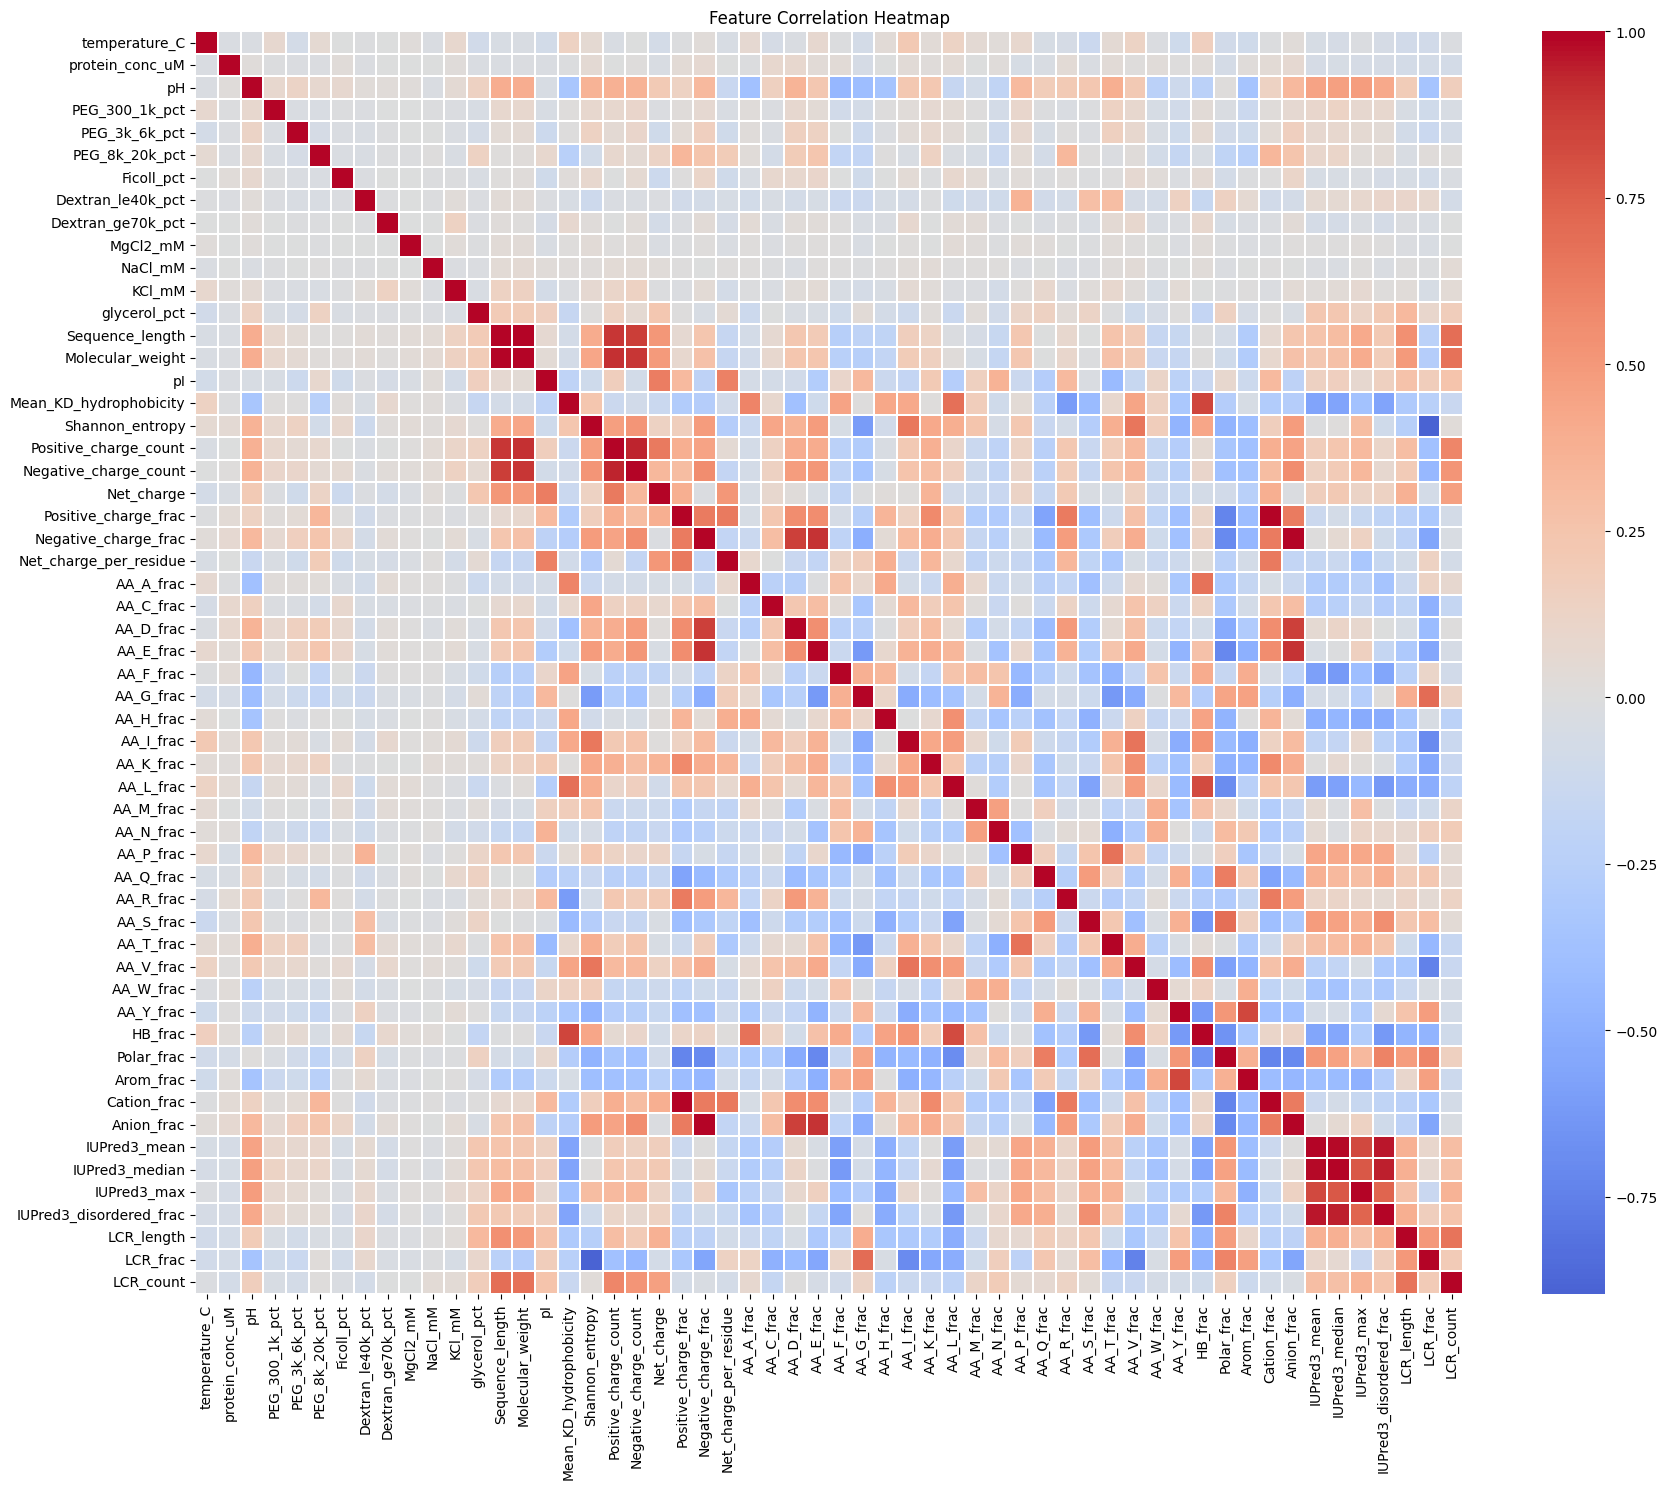

In [ ]:

# FEATURE CORRELATION HEATMAP
# ==========================================

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Numerical features only
numeric_features = df.select_dtypes(include=np.number).columns.tolist()

# Remove target
numeric_features.remove("Label")

corr = df[numeric_features].corr()

plt.figure(figsize=(18, 15))

sns.heatmap(
    corr,
    cmap="coolwarm",
    center=0,
    linewidths=0.3
)

plt.title("Feature Correlation Heatmap")
plt.tight_layout()
plt.show()

In [ ]:
#  HIGHLY CORRELATED FEATURE PAIRS

corr_matrix = df[numeric_features].corr().abs()

# Keep only upper triangle
upper = corr_matrix.where(
    np.triu(np.ones(corr_matrix.shape), k=1).astype(bool)
)

# Extract pairs with correlation >= 0.80
high_corr = (
    upper.stack()
    .reset_index()
)

high_corr.columns = ["Feature 1", "Feature 2", "Correlation"]

high_corr = high_corr[
    high_corr["Correlation"] >= 0.80
].sort_values(
    "Correlation",
    ascending=False
)

display(high_corr)

,Feature 1,Feature 2,Correlation
970,Positive_charge_frac,Cation_frac,1.000000
1004,Negative_charge_frac,Anion_frac,1.000000
637,Sequence_length,Molecular_weight,0.996167
1519,IUPred3_mean,IUPred3_median,0.982426
1521,IUPred3_mean,IUPred3_disordered_frac,0.960393
1526,IUPred3_median,IUPred3_disordered_frac,0.947226
837,Positive_charge_count,Negative_charge_count,0.936589
682,Molecular_weight,Positive_charge_count,0.909427
1154,AA_E_frac,Anion_frac,0.896463
983,Negative_charge_frac,AA_E_frac,0.896463


In [ ]:
# 4C. FEATURE vs TARGET CORRELATION

target_corr = (
    df[numeric_features + ["Label"]]
    .corr()["Label"]
    .drop("Label")
    .sort_values()
)

print("Negative correlation:")
display(target_corr.head(10).to_frame("Correlation"))

print("Positive correlation:")
display(target_corr.tail(10).sort_values(ascending=False).to_frame("Correlation"))

Negative correlation:


,Correlation
HB_frac,-0.256961
AA_F_frac,-0.255809
AA_A_frac,-0.241929
Mean_KD_hydrophobicity,-0.225661
AA_H_frac,-0.214380
AA_L_frac,-0.212390
AA_E_frac,-0.077195
AA_C_frac,-0.072080
temperature_C,-0.068125
protein_conc_uM,-0.062062


Positive correlation:


,Correlation
IUPred3_disordered_frac,0.216182
IUPred3_median,0.214107
LCR_length,0.208514
IUPred3_mean,0.205335
AA_S_frac,0.197529
Polar_frac,0.185087
Net_charge,0.177683
AA_Q_frac,0.159115
IUPred3_max,0.156769
LCR_count,0.149647


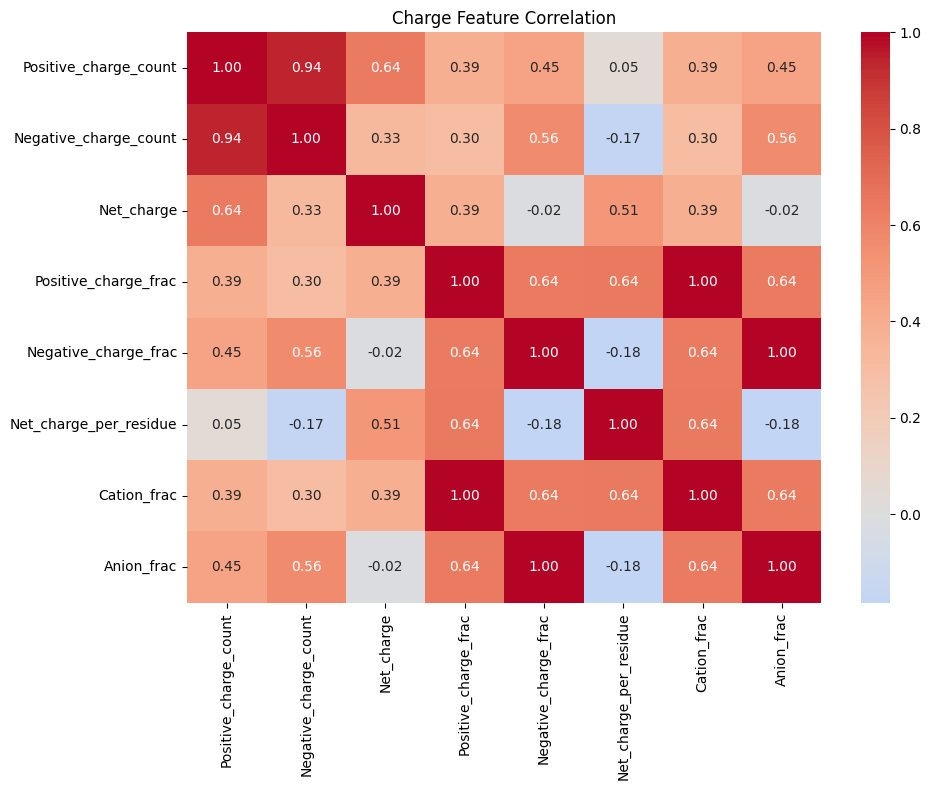

In [ ]:
# 4D. CHARGE FEATURE RELATIONSHIPS

charge_features = [
    "Positive_charge_count",
    "Negative_charge_count",
    "Net_charge",
    "Positive_charge_frac",
    "Negative_charge_frac",
    "Net_charge_per_residue",
    "Cation_frac",
    "Anion_frac"
]

charge_features = [
    x for x in charge_features
    if x in df.columns
]

plt.figure(figsize=(10, 8))

sns.heatmap(
    df[charge_features].corr(),
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Charge Feature Correlation")
plt.tight_layout()
plt.show()

In [ ]:
# 4E. VERY HIGH CORRELATION (>0.95)

very_high_corr = high_corr[
    high_corr["Correlation"] >= 0.95
]

print("Feature pairs with correlation >= 0.95:")
display(very_high_corr)

Feature pairs with correlation >= 0.95:


,Feature 1,Feature 2,Correlation
970,Positive_charge_frac,Cation_frac,1.000000
1004,Negative_charge_frac,Anion_frac,1.000000
637,Sequence_length,Molecular_weight,0.996167
1519,IUPred3_mean,IUPred3_median,0.982426
1521,IUPred3_mean,IUPred3_disordered_frac,0.960393


In [ ]:
#  OUTLIER COUNT USING IQR

import numpy as np
import pandas as pd

numeric_features = df.select_dtypes(include=np.number).columns.tolist()
numeric_features.remove("Label")

outlier_summary = []

for feature in numeric_features:

    Q1 = df[feature].quantile(0.25)
    Q3 = df[feature].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = ((df[feature] < lower) | (df[feature] > upper)).sum()

    outlier_summary.append({
        "Feature": feature,
        "Lower_bound": lower,
        "Upper_bound": upper,
        "Outlier_count": outliers,
        "Outlier_%": round(outliers / len(df) * 100, 2)
    })

outlier_summary = pd.DataFrame(outlier_summary)

display(
    outlier_summary
    .sort_values("Outlier_count", ascending=False)
)

,Feature,Lower_bound,Upper_bound,Outlier_count,Outlier_%
0,temperature_C,0.416667,0.416667,7604,36.70
1,protein_conc_uM,-0.101750,0.189050,3158,15.24
35,AA_N_frac,-0.026300,0.117908,2635,12.72
10,NaCl_mM,-0.155000,0.285000,2462,11.88
2,pH,0.410714,0.610714,2441,11.78
51,IUPred3_max,0.676248,1.162072,2423,11.69
53,LCR_length,-112.000000,288.000000,2279,11.00
11,KCl_mM,0.000000,0.000000,2065,9.97
34,AA_M_frac,-0.018832,0.057276,2028,9.79
12,glycerol_pct,0.000000,0.000000,1982,9.57


In [ ]:
# . BIOLOGICAL / EXPERIMENTAL RANGE CHECK

checks = {}

checks["Negative temperature"] = df[df["temperature_C"] < 0]
checks["Invalid pH"] = df[(df["pH"] < 0) | (df["pH"] > 14)]
checks["Negative protein concentration"] = df[df["protein_conc_uM"] < 0]
checks["Negative NaCl"] = df[df["NaCl_mM"] < 0]
checks["Negative KCl"] = df[df["KCl_mM"] < 0]
checks["Negative MgCl2"] = df[df["MgCl2_mM"] < 0]
checks["Negative glycerol"] = df[df["glycerol_pct"] < 0]

for name, result in checks.items():
    print(f"{name}: {len(result)} rows")

Negative temperature: 1 rows
Invalid pH: 0 rows
Negative protein concentration: 0 rows
Negative NaCl: 0 rows
Negative KCl: 0 rows
Negative MgCl2: 0 rows
Negative glycerol: 0 rows


In [ ]:


percentage_features = [
    "PEG_300_1k_pct",
    "PEG_3k_6k_pct",
    "PEG_8k_20k_pct",
    "Ficoll_pct",
    "Dextran_le40k_pct",
    "Dextran_ge70k_pct",
    "glycerol_pct"
]

for feature in percentage_features:

    if feature not in df.columns:
        continue

    invalid = df[
        (df[feature] < 0) |
        (df[feature] > 100)
    ]

    print(f"{feature}: {len(invalid)} invalid rows")

PEG_300_1k_pct: 0 invalid rows
PEG_3k_6k_pct: 0 invalid rows
PEG_8k_20k_pct: 0 invalid rows
Ficoll_pct: 0 invalid rows
Dextran_le40k_pct: 0 invalid rows
Dextran_ge70k_pct: 0 invalid rows
glycerol_pct: 0 invalid rows


In [ ]:


checks = {
    "Sequence length <= 0":
        df[df["Sequence_length"] <= 0],

    "Molecular weight <= 0":
        df[df["Molecular_weight"] <= 0],

    "pI outside 0-14":
        df[(df["pI"] < 0) | (df["pI"] > 14)],

    "Disordered fraction outside 0-1":
        df[
            (df["IUPred3_disordered_frac"] < 0) |
            (df["IUPred3_disordered_frac"] > 1)
        ],

    "LCR fraction outside 0-1":
        df[
            (df["LCR_frac"] < 0) |
            (df["LCR_frac"] > 1)
        ],

    "Net charge per residue outside -1 to +1":
        df[
            (df["Net_charge_per_residue"] < -1) |
            (df["Net_charge_per_residue"] > 1)
        ]
}

for name, result in checks.items():
    print(f"{name}: {len(result)} rows")

Sequence length <= 0: 0 rows
Molecular weight <= 0: 0 rows
pI outside 0-14: 0 rows
Disordered fraction outside 0-1: 0 rows
LCR fraction outside 0-1: 0 rows
Net charge per residue outside -1 to +1: 0 rows


In [ ]:
df.isnull().sum()

,0
PSID,0
Protein_ID,0
Sequence,0
Label,0
temperature_C,0
protein_conc_uM,0
pH,0
PEG_300_1k_pct,0
PEG_3k_6k_pct,0
PEG_8k_20k_pct,0


In [ ]:
#as ma'am told





#

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load dataset
df = pd.read_csv('/content/LLPSDB_v2_model_dataset.csv')

print("Dataset shape:", df.shape)
print("\nNumber of rows:", len(df))
print("Number of features:", len(df.columns))

print("\nColumns:")
for i, col in enumerate(df.columns, 1):
    print(i, col)

Dataset shape: (20719, 60)

Number of rows: 20719
Number of features: 60

Columns:
1 PSID
2 Protein_ID
3 Sequence
4 Label
5 temperature_C
6 protein_conc_uM
7 pH
8 PEG_300_1k_pct
9 PEG_3k_6k_pct
10 PEG_8k_20k_pct
11 Ficoll_pct
12 Dextran_le40k_pct
13 Dextran_ge70k_pct
14 MgCl2_mM
15 NaCl_mM
16 KCl_mM
17 glycerol_pct
18 Sequence_length
19 Molecular_weight
20 pI
21 Mean_KD_hydrophobicity
22 Shannon_entropy
23 Positive_charge_count
24 Negative_charge_count
25 Net_charge
26 Positive_charge_frac
27 Negative_charge_frac
28 Net_charge_per_residue
29 AA_A_frac
30 AA_C_frac
31 AA_D_frac
32 AA_E_frac
33 AA_F_frac
34 AA_G_frac
35 AA_H_frac
36 AA_I_frac
37 AA_K_frac
38 AA_L_frac
39 AA_M_frac
40 AA_N_frac
41 AA_P_frac
42 AA_Q_frac
43 AA_R_frac
44 AA_S_frac
45 AA_T_frac
46 AA_V_frac
47 AA_W_frac
48 AA_Y_frac
49 HB_frac
50 Polar_frac
51 Arom_frac
52 Cation_frac
53 Anion_frac
54 IUPred3_mean
55 IUPred3_median
56 IUPred3_max
57 IUPred3_disordered_frac
58 LCR_length
59 LCR_frac
60 LCR_count


In [ ]:
print(df['Label'].value_counts())
print("\nPercentage:")
print(df['Label'].value_counts(normalize=True) * 100)

Label
1    11660
0     9059
Name: count, dtype: int64

Percentage:
Label
1    56.276847
0    43.723153
Name: proportion, dtype: float64


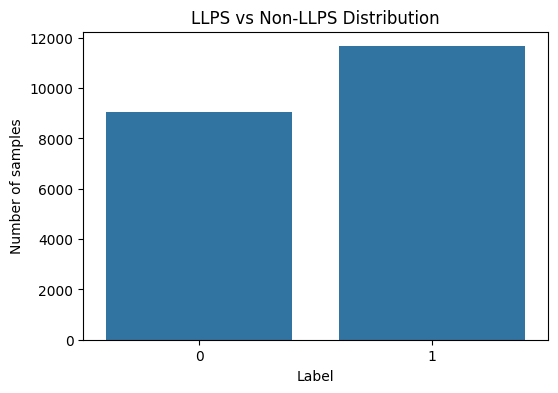

In [ ]:
plt.figure(figsize=(6, 4))

sns.countplot(data=df, x='Label')

plt.title('LLPS vs Non-LLPS Distribution')
plt.xlabel('Label')
plt.ylabel('Number of samples')
plt.show()

In [ ]:
missing = df.isnull().sum()

missing = missing[missing > 0].sort_values(ascending=False)

print(missing)

Series([], dtype: int64)


In [ ]:
print("Total missing values:", df.isnull().sum().sum())

Total missing values: 0


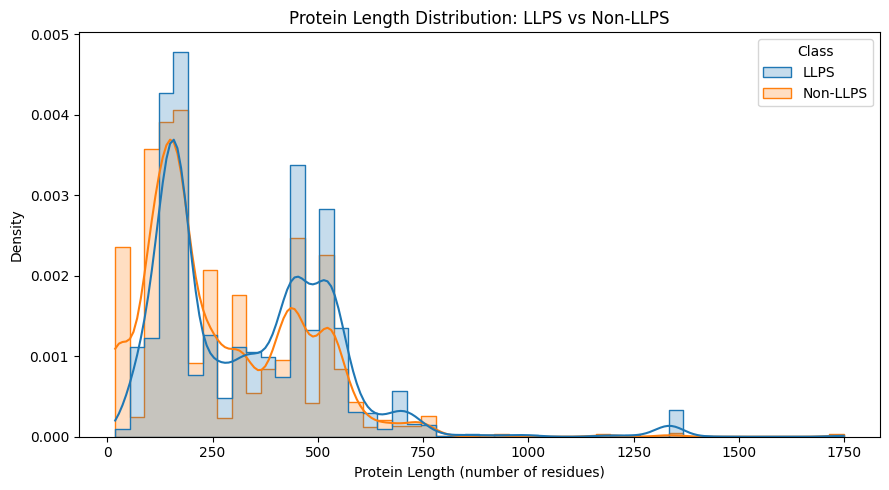

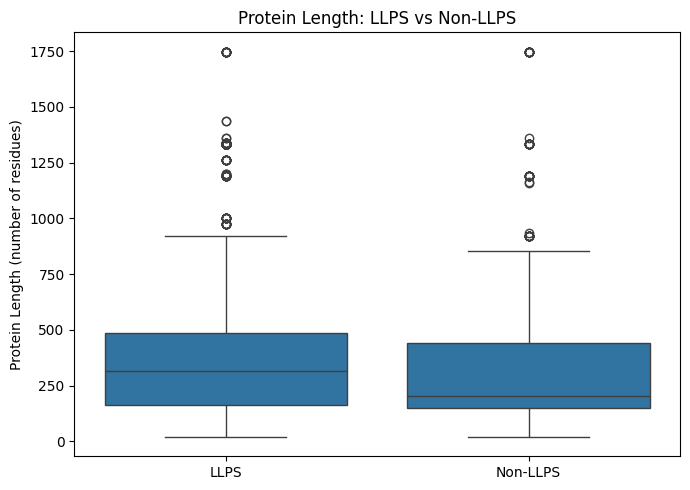

In [ ]:
# Protein Length
# Create readable labels
df['Class'] = df['Label'].map({
    1: 'LLPS',
    0: 'Non-LLPS'
})

# -------------------------------
# Histogram
# -------------------------------

plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x='Sequence_length',
    hue='Class',
    bins=50,
    kde=True,
    element='step',
    stat='density',
    common_norm=False
)

plt.title('Protein Length Distribution: LLPS vs Non-LLPS')
plt.xlabel('Protein Length (number of residues)')
plt.ylabel('Density')
plt.tight_layout()
plt.show()


# -------------------------------
# Box Plot
# -------------------------------

plt.figure(figsize=(7, 5))

sns.boxplot(
    data=df,
    x='Class',
    y='Sequence_length'
)

plt.title('Protein Length: LLPS vs Non-LLPS')
plt.xlabel('')
plt.ylabel('Protein Length (number of residues)')
plt.tight_layout()
plt.show()

In [ ]:
print(
    df.groupby('Class')['Sequence_length']
      .describe()
      .round(2)
)

            count    mean     std   min    25%    50%    75%     max
Class                                                               
LLPS      11660.0  337.13  217.65  19.0  162.0  316.0  486.0  1748.0
Non-LLPS   9059.0  274.26  193.19  19.0  147.0  202.0  441.0  1748.0


In [ ]:
# Molecular weight

In [ ]:
df['Molecular_weight'].describe()

,Molecular_weight
count,20719.000000
mean,32819.427382
std,22589.407510
min,1828.712600
25%,14651.488800
50%,27771.376900
75%,48200.056900
max,195456.564900


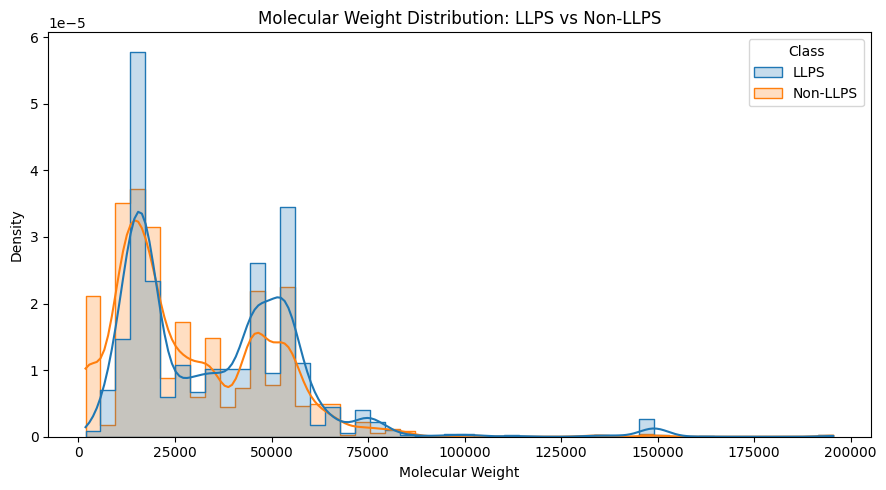

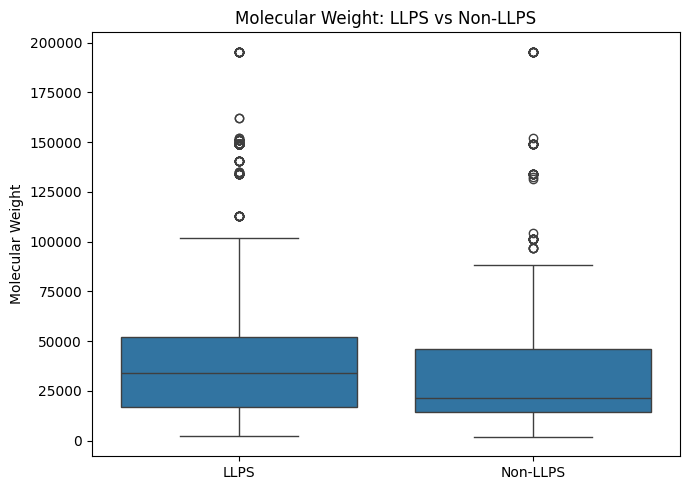

In [ ]:


plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x='Molecular_weight',
    hue='Class',
    bins=50,
    kde=True,
    element='step',
    stat='density',
    common_norm=False
)

plt.title('Molecular Weight Distribution: LLPS vs Non-LLPS')
plt.xlabel('Molecular Weight')
plt.ylabel('Density')
plt.tight_layout()
plt.show()




plt.figure(figsize=(7, 5))

sns.boxplot(
    data=df,
    x='Class',
    y='Molecular_weight'
)

plt.title('Molecular Weight: LLPS vs Non-LLPS')
plt.xlabel('')
plt.ylabel('Molecular Weight')
plt.tight_layout()
plt.show()

In [ ]:
print(
    df.groupby('Class')['Molecular_weight']
      .describe()
      .round(2)
)

            count      mean       std      min       25%       50%       75%  \
Class                                                                          
LLPS      11660.0  35655.57  23499.46  2257.62  16839.67  33968.79  52205.65   
Non-LLPS   9059.0  29168.98  20800.69  1828.71  14450.31  21464.42  45849.35   

                max  
Class                
LLPS      195456.56  
Non-LLPS  195456.56  


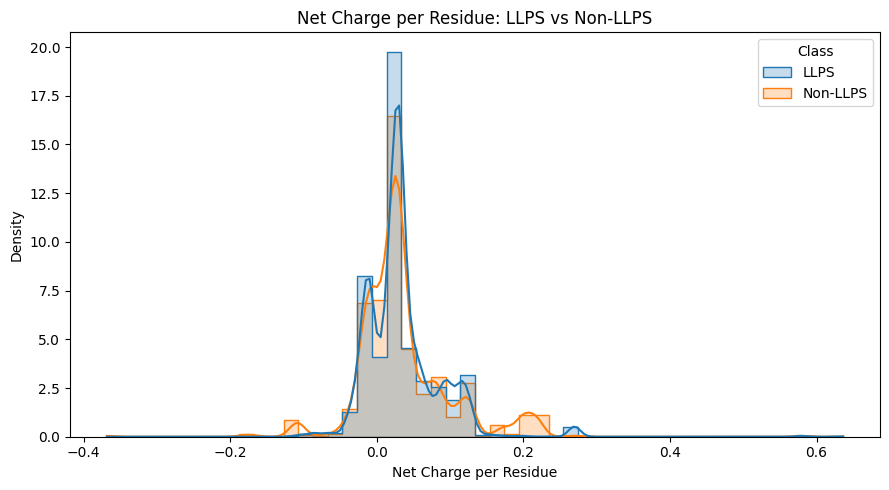

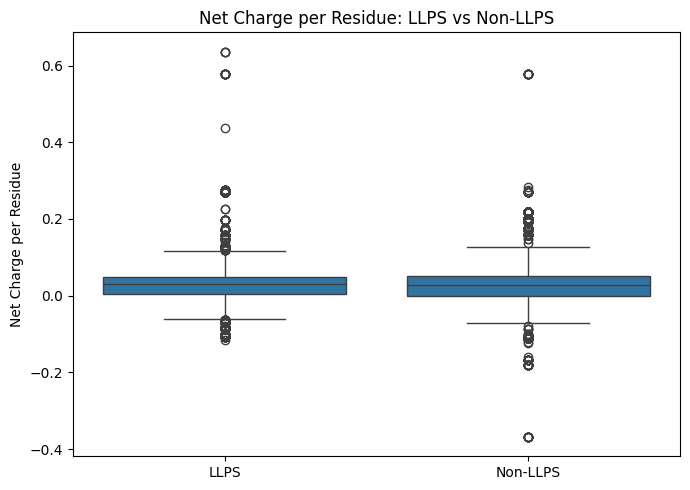

In [ ]:
# Net Charge per Residue


plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x='Net_charge_per_residue',
    hue='Class',
    bins=50,
    kde=True,
    element='step',
    stat='density',
    common_norm=False
)

plt.title('Net Charge per Residue: LLPS vs Non-LLPS')
plt.xlabel('Net Charge per Residue')
plt.ylabel('Density')
plt.tight_layout()
plt.show()



plt.figure(figsize=(7, 5))

sns.boxplot(
    data=df,
    x='Class',
    y='Net_charge_per_residue'
)

plt.title('Net Charge per Residue: LLPS vs Non-LLPS')
plt.xlabel('')
plt.ylabel('Net Charge per Residue')
plt.tight_layout()
plt.show()

In [ ]:
print(
    df.groupby('Class')['Net_charge_per_residue']
      .describe()
      .round(4)
)

            count    mean     std     min     25%     50%     75%     max
Class                                                                    
LLPS      11660.0  0.0345  0.0515 -0.1163  0.0045  0.0294  0.0500  0.6364
Non-LLPS   9059.0  0.0359  0.0646 -0.3684  0.0000  0.0268  0.0511  0.5789


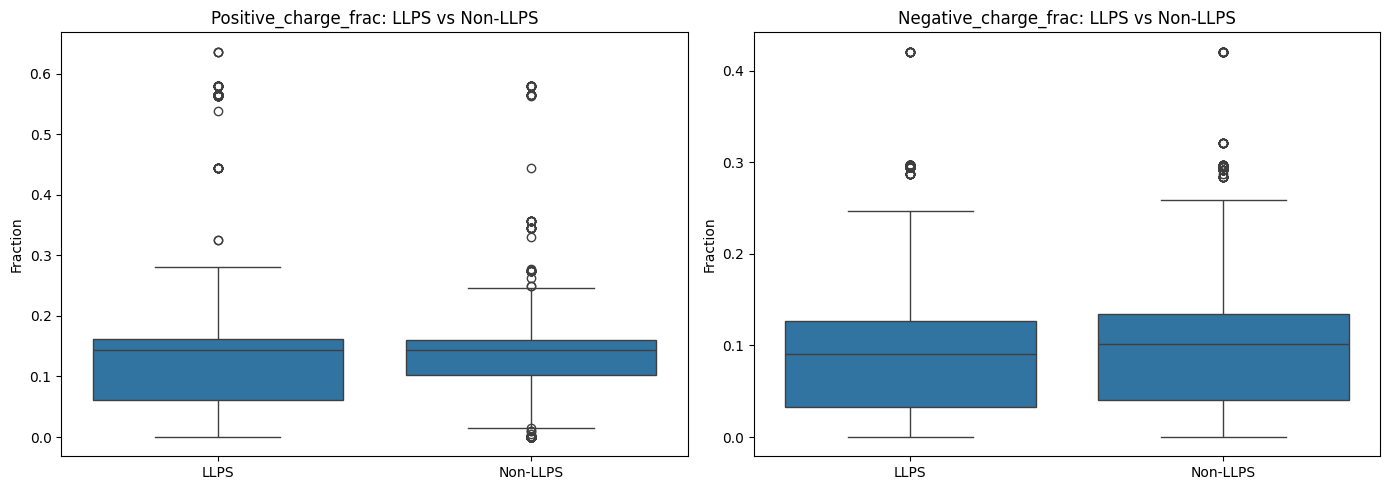

In [ ]:
charge_features = [
    'Positive_charge_frac',
    'Negative_charge_frac'
]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, feature in zip(axes, charge_features):

    sns.boxplot(
        data=df,
        x='Class',
        y=feature,
        ax=ax
    )

    ax.set_title(f'{feature}: LLPS vs Non-LLPS')
    ax.set_xlabel('')
    ax.set_ylabel('Fraction')

plt.tight_layout()
plt.show()

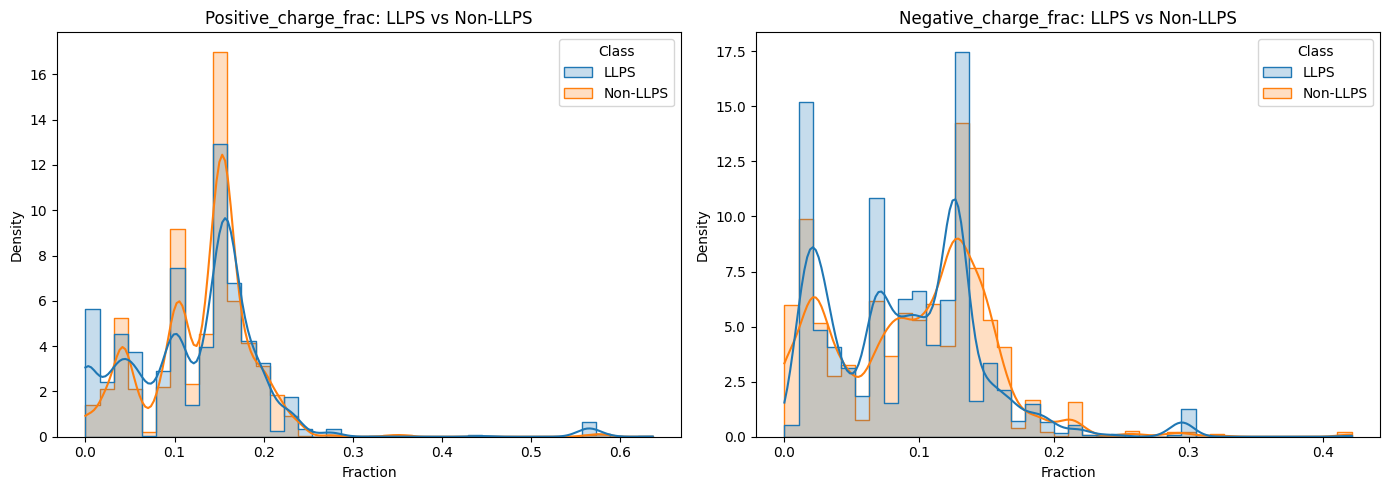

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, feature in zip(axes, charge_features):

    sns.histplot(
        data=df,
        x=feature,
        hue='Class',
        bins=40,
        kde=True,
        element='step',
        stat='density',
        common_norm=False,
        ax=ax
    )

    ax.set_title(f'{feature}: LLPS vs Non-LLPS')
    ax.set_xlabel('Fraction')
    ax.set_ylabel('Density')

plt.tight_layout()
plt.show()

In [ ]:
print(
    df.groupby('Class')[charge_features]
      .describe()
      .round(4)
)

         Positive_charge_frac                                               \
                        count    mean     std  min     25%     50%     75%   
Class                                                                        
LLPS                  11660.0  0.1248  0.0818  0.0  0.0611  0.1429  0.1614   
Non-LLPS               9059.0  0.1311  0.0608  0.0  0.1026  0.1442  0.1609   

                 Negative_charge_frac                                       \
             max                count    mean     std  min     25%     50%   
Class                                                                        
LLPS      0.6364              11660.0  0.0903  0.0564  0.0  0.0329  0.0902   
Non-LLPS  0.5789               9059.0  0.0952  0.0583  0.0  0.0400  0.1012   

                          
             75%     max  
Class                     
LLPS      0.1270  0.4211  
Non-LLPS  0.1342  0.4211  


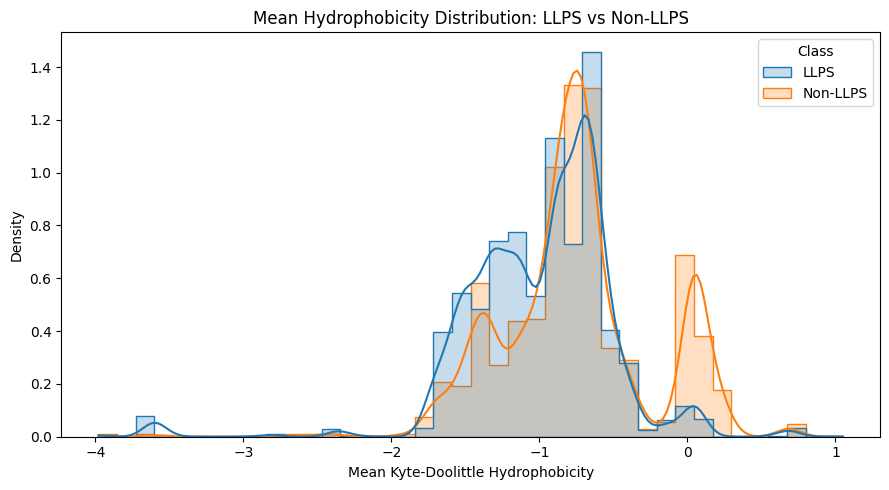

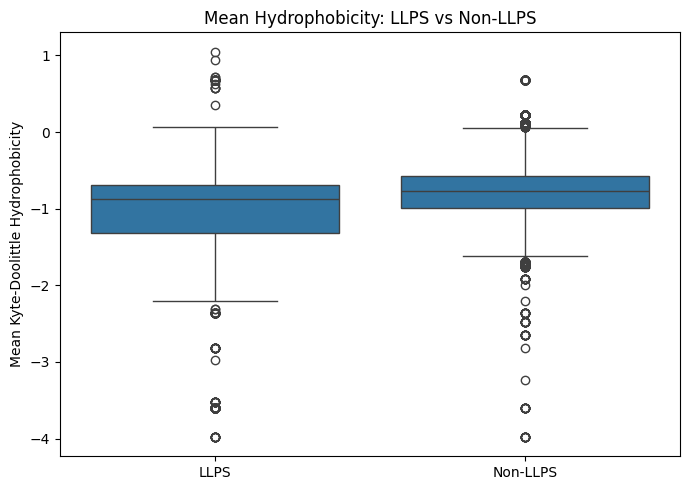

In [ ]:
feature = 'Mean_KD_hydrophobicity'



plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x=feature,
    hue='Class',
    bins=40,
    kde=True,
    element='step',
    stat='density',
    common_norm=False
)

plt.title('Mean Hydrophobicity Distribution: LLPS vs Non-LLPS')
plt.xlabel('Mean Kyte-Doolittle Hydrophobicity')
plt.ylabel('Density')
plt.tight_layout()
plt.show()



plt.figure(figsize=(7, 5))

sns.boxplot(
    data=df,
    x='Class',
    y=feature
)

plt.title('Mean Hydrophobicity: LLPS vs Non-LLPS')
plt.xlabel('')
plt.ylabel('Mean Kyte-Doolittle Hydrophobicity')
plt.tight_layout()
plt.show()

In [ ]:
print(
    df.groupby('Class')[feature]
      .describe()
      .round(4)
)

            count    mean     std     min     25%     50%     75%     max
Class                                                                    
LLPS      11660.0 -0.9944  0.5035 -3.9789 -1.3177 -0.8788 -0.6899  1.0500
Non-LLPS   9059.0 -0.7568  0.5157 -3.9789 -0.9961 -0.7663 -0.5717  0.6853


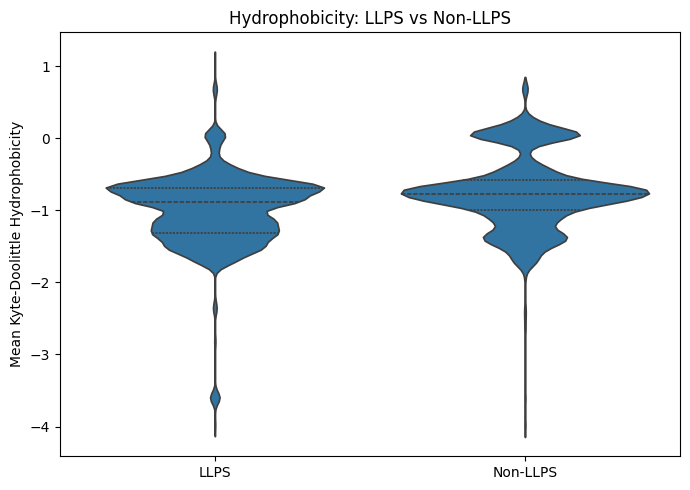

In [ ]:
plt.figure(figsize=(7, 5))

sns.violinplot(
    data=df,
    x='Class',
    y='Mean_KD_hydrophobicity',
    inner='quartile'
)

plt.title('Hydrophobicity: LLPS vs Non-LLPS')
plt.xlabel('')
plt.ylabel('Mean Kyte-Doolittle Hydrophobicity')
plt.tight_layout()
plt.show()

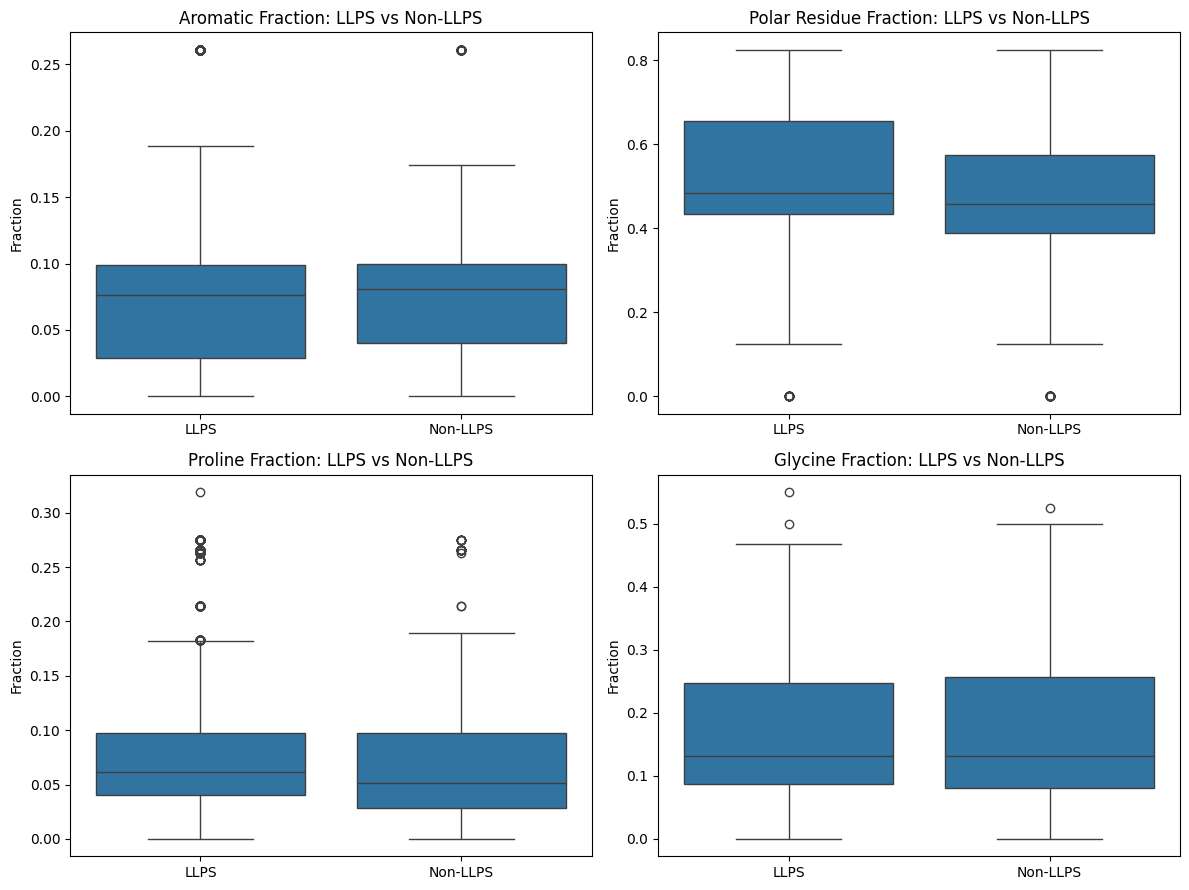

In [ ]:
composition_features = {
    'Arom_frac': 'Aromatic Fraction',
    'Polar_frac': 'Polar Residue Fraction',
    'AA_P_frac': 'Proline Fraction',
    'AA_G_frac': 'Glycine Fraction'
}

fig, axes = plt.subplots(2, 2, figsize=(12, 9))

for ax, (feature, title) in zip(axes.flat, composition_features.items()):

    sns.boxplot(
        data=df,
        x='Class',
        y=feature,
        ax=ax
    )

    ax.set_title(f'{title}: LLPS vs Non-LLPS')
    ax.set_xlabel('')
    ax.set_ylabel('Fraction')

plt.tight_layout()
plt.show()

In [ ]:
print(
    df.groupby('Class')[list(composition_features.keys())]
      .describe()
      .round(4)
)

         Arom_frac                                                       \
             count    mean     std  min     25%     50%     75%     max   
Class                                                                     
LLPS       11660.0  0.0754  0.0509  0.0  0.0286  0.0761  0.0992  0.2609   
Non-LLPS    9059.0  0.0752  0.0393  0.0  0.0405  0.0805  0.0996  0.2609   

         Polar_frac          ... AA_P_frac         AA_G_frac                  \
              count    mean  ...       75%     max     count    mean     std   
Class                        ...                                               
LLPS        11660.0  0.5291  ...    0.0975  0.3189   11660.0  0.1636  0.1011   
Non-LLPS     9059.0  0.4768  ...    0.0971  0.2751    9059.0  0.1687  0.1094   

                                              
          min     25%     50%     75%    max  
Class                                         
LLPS      0.0  0.0865  0.1308  0.2474  0.550  
Non-LLPS  0.0  0.0805  0.1308  0.25

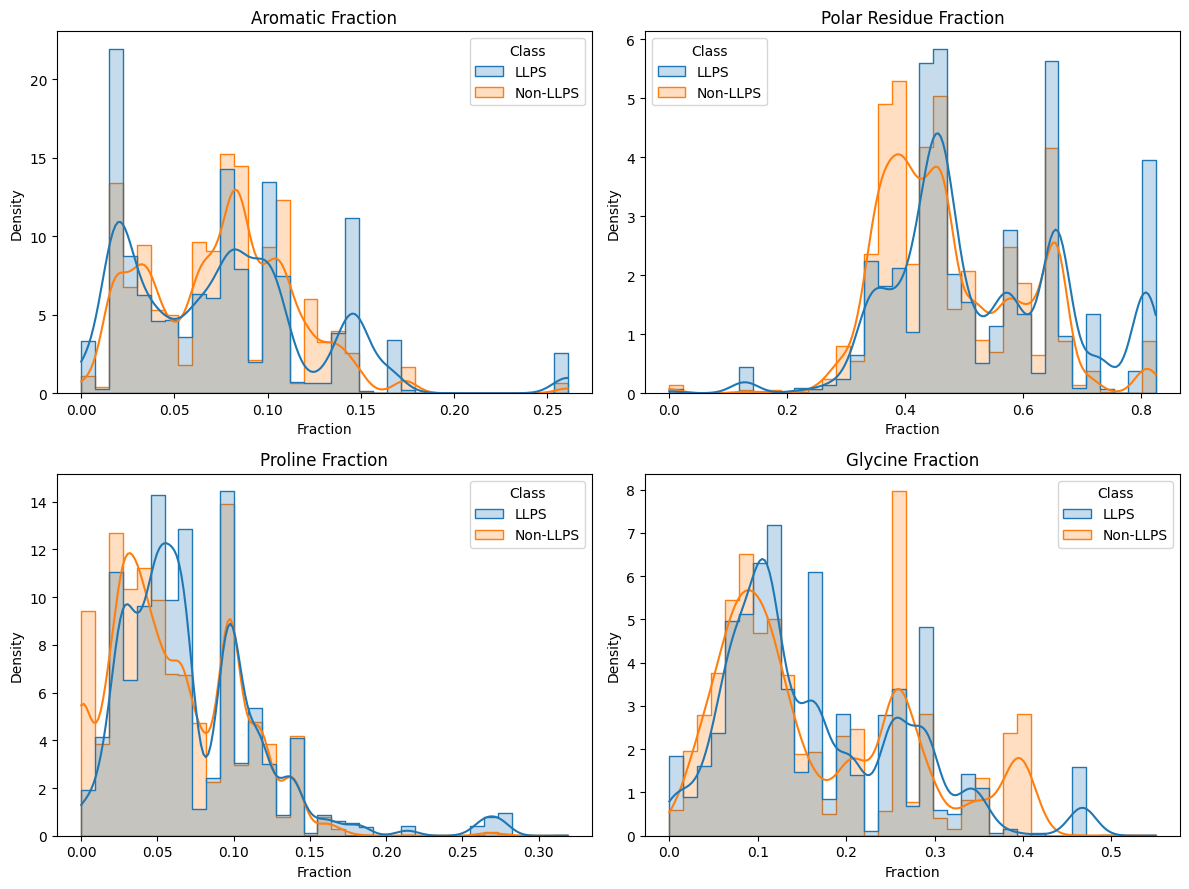

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(12, 9))

for ax, (feature, title) in zip(axes.flat, composition_features.items()):

    sns.histplot(
        data=df,
        x=feature,
        hue='Class',
        bins=35,
        kde=True,
        element='step',
        stat='density',
        common_norm=False,
        ax=ax
    )

    ax.set_title(title)
    ax.set_xlabel('Fraction')
    ax.set_ylabel('Density')

plt.tight_layout()
plt.show()

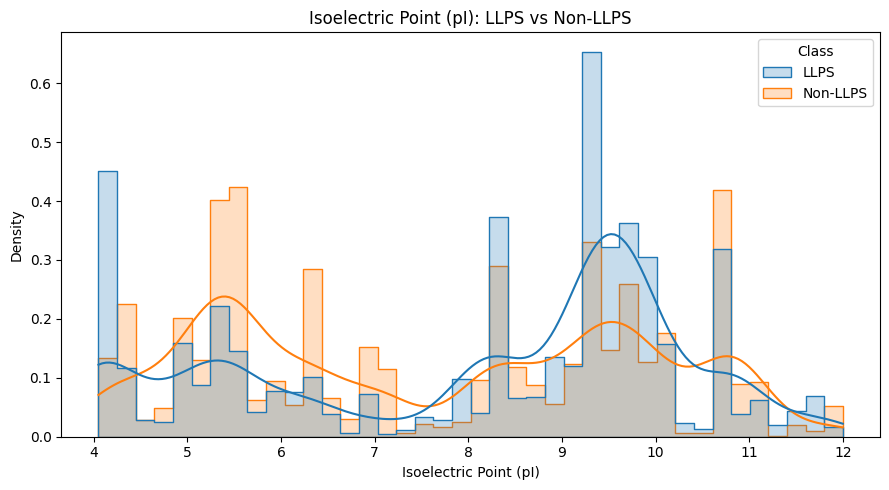

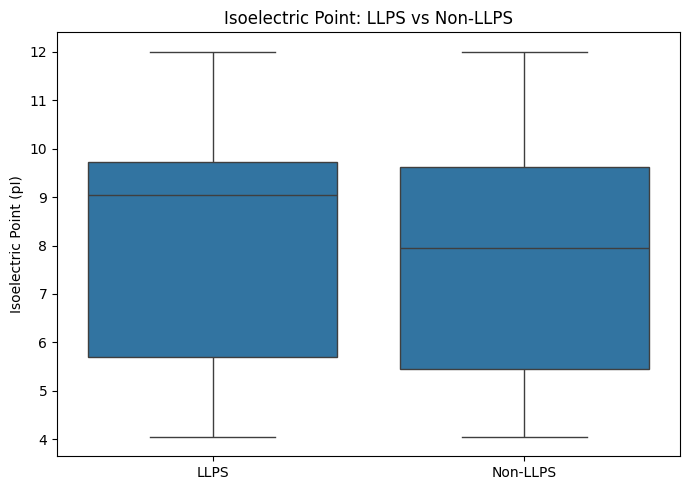

In [ ]:
feature = 'pI'


plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x=feature,
    hue='Class',
    bins=40,
    kde=True,
    element='step',
    stat='density',
    common_norm=False
)

plt.title('Isoelectric Point (pI): LLPS vs Non-LLPS')
plt.xlabel('Isoelectric Point (pI)')
plt.ylabel('Density')
plt.tight_layout()
plt.show()



plt.figure(figsize=(7, 5))

sns.boxplot(
    data=df,
    x='Class',
    y=feature
)

plt.title('Isoelectric Point: LLPS vs Non-LLPS')
plt.xlabel('')
plt.ylabel('Isoelectric Point (pI)')
plt.tight_layout()
plt.show()

In [ ]:
print(
    df.groupby('Class')['pI']
      .describe()
      .round(3)
)

            count   mean    std   min    25%    50%    75%   max
Class                                                           
LLPS      11660.0  8.069  2.262  4.05  5.709  9.035  9.728  12.0
Non-LLPS   9059.0  7.633  2.236  4.05  5.455  7.944  9.616  12.0


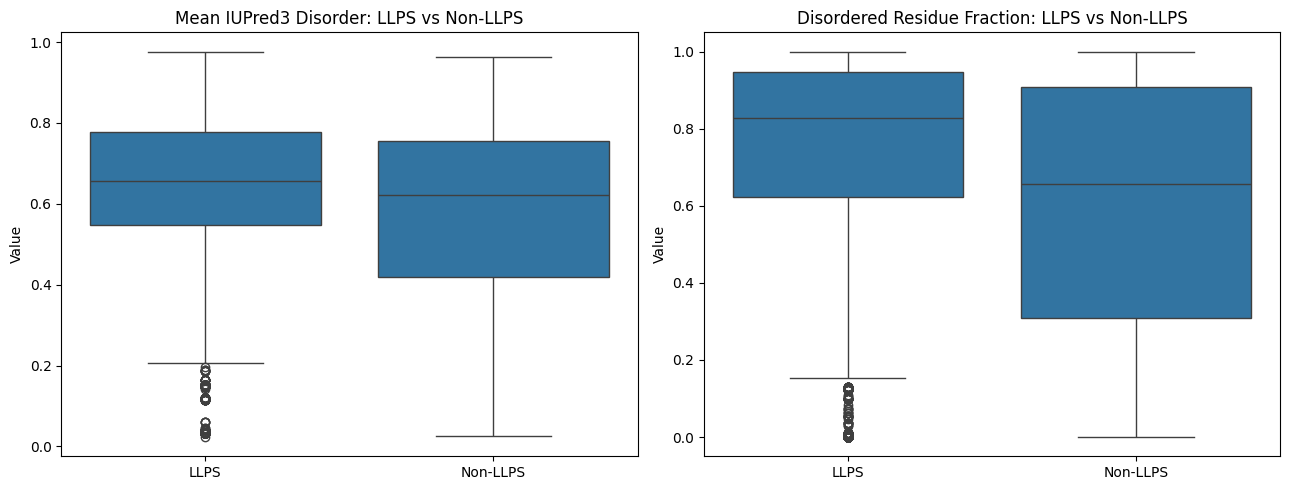

In [ ]:
disorder_features = {
    'IUPred3_mean': 'Mean IUPred3 Disorder',
    'IUPred3_disordered_frac': 'Disordered Residue Fraction'
}

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, (feature, title) in zip(axes, disorder_features.items()):

    sns.boxplot(
        data=df,
        x='Class',
        y=feature,
        ax=ax
    )

    ax.set_title(f'{title}: LLPS vs Non-LLPS')
    ax.set_xlabel('')
    ax.set_ylabel('Value')

plt.tight_layout()
plt.show()

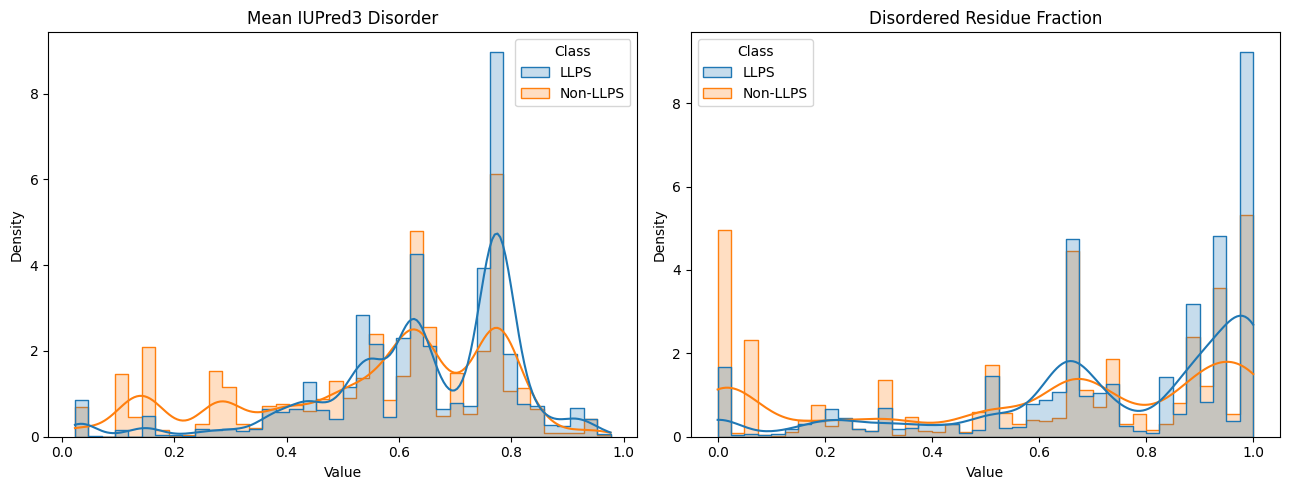

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, (feature, title) in zip(axes, disorder_features.items()):

    sns.histplot(
        data=df,
        x=feature,
        hue='Class',
        bins=40,
        kde=True,
        element='step',
        stat='density',
        common_norm=False,
        ax=ax
    )

    ax.set_title(title)
    ax.set_xlabel('Value')
    ax.set_ylabel('Density')

plt.tight_layout()
plt.show()

In [ ]:
print(
    df.groupby('Class')[list(disorder_features.keys())]
      .describe()
      .round(4)
)

         IUPred3_mean                                                          \
                count    mean     std     min     25%     50%     75%     max   
Class                                                                           
LLPS          11660.0  0.6415  0.1765  0.0234  0.5469  0.6555  0.7787  0.9766   
Non-LLPS       9059.0  0.5582  0.2207  0.0251  0.4187  0.6213  0.7550  0.9622   

         IUPred3_disordered_frac                                               \
                           count    mean     std  min     25%     50%     75%   
Class                                                                           
LLPS                     11660.0  0.7306  0.2770  0.0  0.6230  0.8289  0.9471   
Non-LLPS                  9059.0  0.5920  0.3489  0.0  0.3092  0.6577  0.9073   

               
          max  
Class          
LLPS      1.0  
Non-LLPS  1.0  


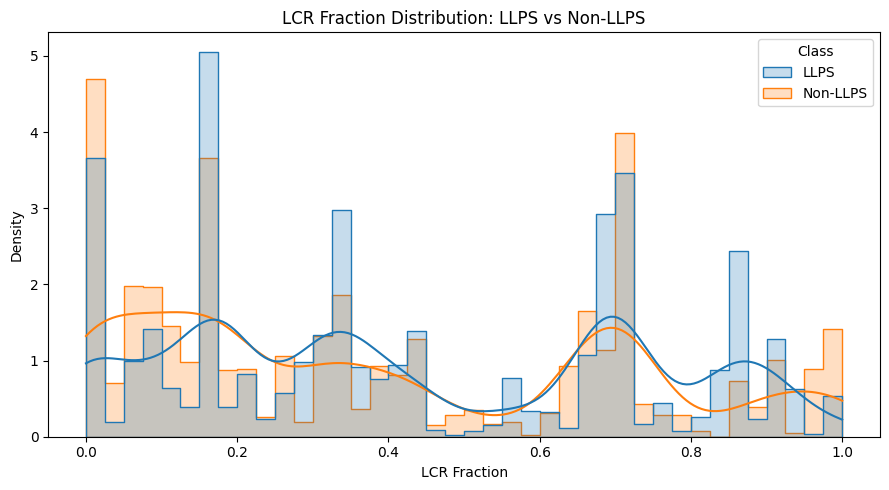

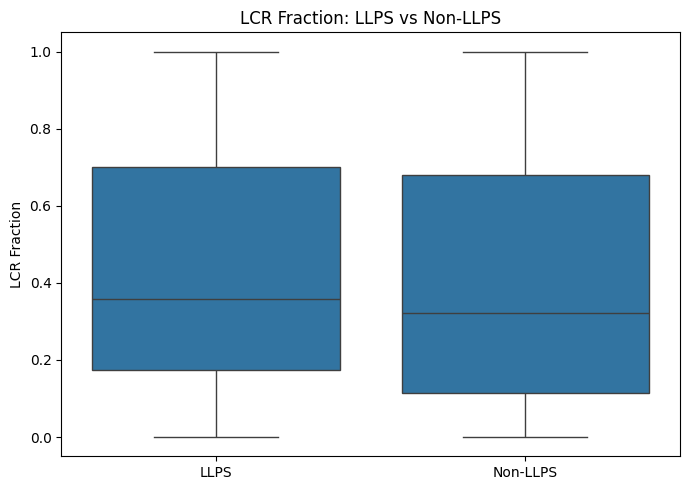

In [ ]:
feature = 'LCR_frac'

plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x=feature,
    hue='Class',
    bins=40,
    kde=True,
    element='step',
    stat='density',
    common_norm=False
)

plt.title('LCR Fraction Distribution: LLPS vs Non-LLPS')
plt.xlabel('LCR Fraction')
plt.ylabel('Density')
plt.tight_layout()
plt.show()


plt.figure(figsize=(7, 5))

sns.boxplot(
    data=df,
    x='Class',
    y=feature
)

plt.title('LCR Fraction: LLPS vs Non-LLPS')
plt.xlabel('')
plt.ylabel('LCR Fraction')
plt.tight_layout()
plt.show()

In [ ]:
print(
    df.groupby('Class')['LCR_frac']
      .describe()
      .round(4)
)

            count    mean     std  min     25%     50%     75%  max
Class                                                              
LLPS      11660.0  0.4332  0.2985  0.0  0.1746  0.3574  0.7013  1.0
Non-LLPS   9059.0  0.3878  0.3116  0.0  0.1154  0.3226  0.6787  1.0


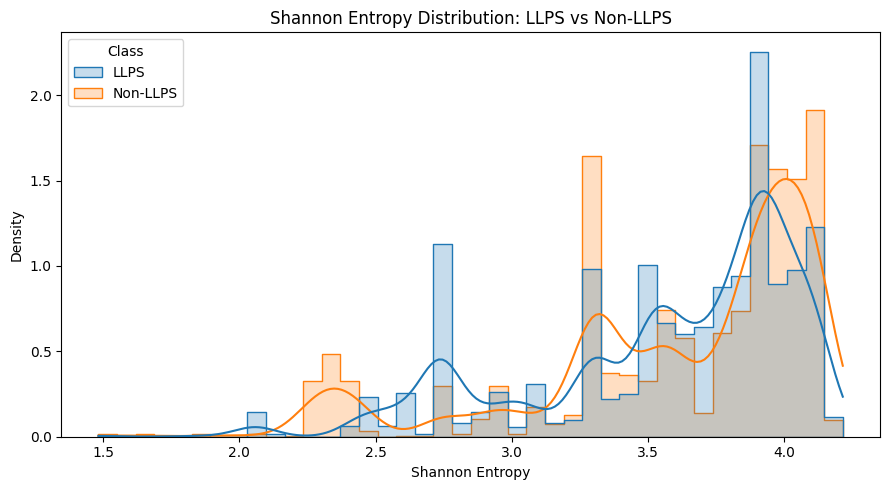

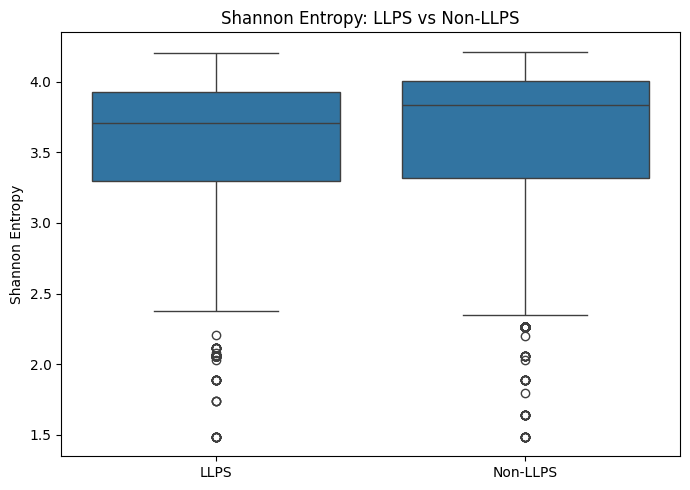

In [ ]:
feature = 'Shannon_entropy'

plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x=feature,
    hue='Class',
    bins=40,
    kde=True,
    element='step',
    stat='density',
    common_norm=False
)

plt.title('Shannon Entropy Distribution: LLPS vs Non-LLPS')
plt.xlabel('Shannon Entropy')
plt.ylabel('Density')
plt.tight_layout()
plt.show()


plt.figure(figsize=(7, 5))

sns.boxplot(
    data=df,
    x='Class',
    y=feature
)

plt.title('Shannon Entropy: LLPS vs Non-LLPS')
plt.xlabel('')
plt.ylabel('Shannon Entropy')
plt.tight_layout()
plt.show()

In [ ]:
print(
    df.groupby('Class')['Shannon_entropy']
      .describe()
      .round(4)
)

            count    mean     std     min     25%     50%     75%     max
Class                                                                    
LLPS      11660.0  3.5692  0.4906  1.4832  3.2977  3.7089  3.9260  4.2071
Non-LLPS   9059.0  3.6085  0.5248  1.4832  3.3204  3.8336  4.0058  4.2143


# **Scatter Plots**

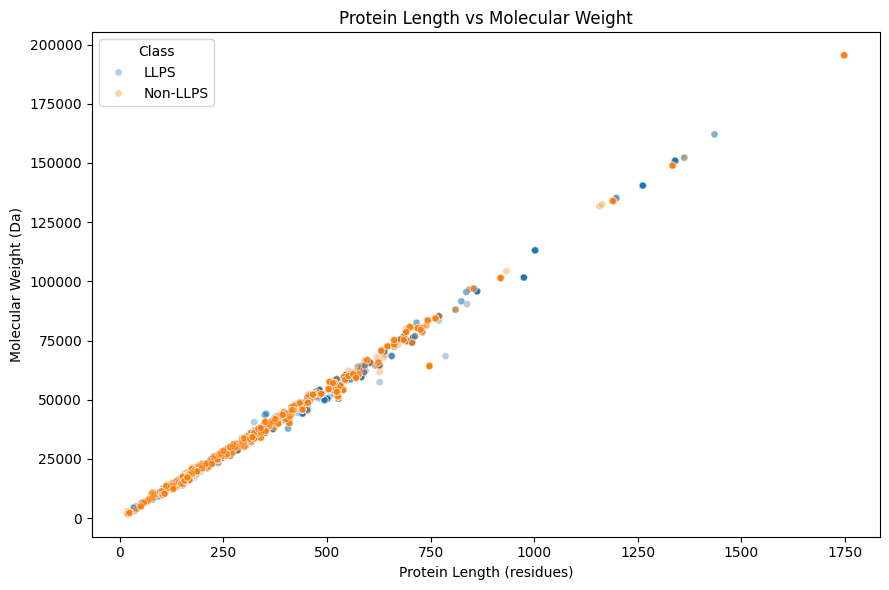

In [ ]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=df,
    x='Sequence_length',
    y='Molecular_weight',
    hue='Class',
    alpha=0.35,
    s=25
)

plt.title('Protein Length vs Molecular Weight')
plt.xlabel('Protein Length (residues)')
plt.ylabel('Molecular Weight (Da)')
plt.tight_layout()
plt.show()

In [ ]:
pearson_corr = df['Sequence_length'].corr(df['Molecular_weight'], method='pearson')
spearman_corr = df['Sequence_length'].corr(df['Molecular_weight'], method='spearman')

print(f"Pearson correlation:  {pearson_corr:.4f}")
print(f"Spearman correlation: {spearman_corr:.4f}")

Pearson correlation:  0.9962
Spearman correlation: 0.9949


In [ ]:
for label in [1, 0]:

    subset = df[df['Label'] == label]

    pearson = subset['Sequence_length'].corr(
        subset['Molecular_weight'],
        method='pearson'
    )

    spearman = subset['Sequence_length'].corr(
        subset['Molecular_weight'],
        method='spearman'
    )

    name = 'LLPS' if label == 1 else 'Non-LLPS'

    print(f'{name}:')
    print(f'  Pearson  = {pearson:.4f}')
    print(f'  Spearman = {spearman:.4f}')

LLPS:
  Pearson  = 0.9964
  Spearman = 0.9943
Non-LLPS:
  Pearson  = 0.9957
  Spearman = 0.9946


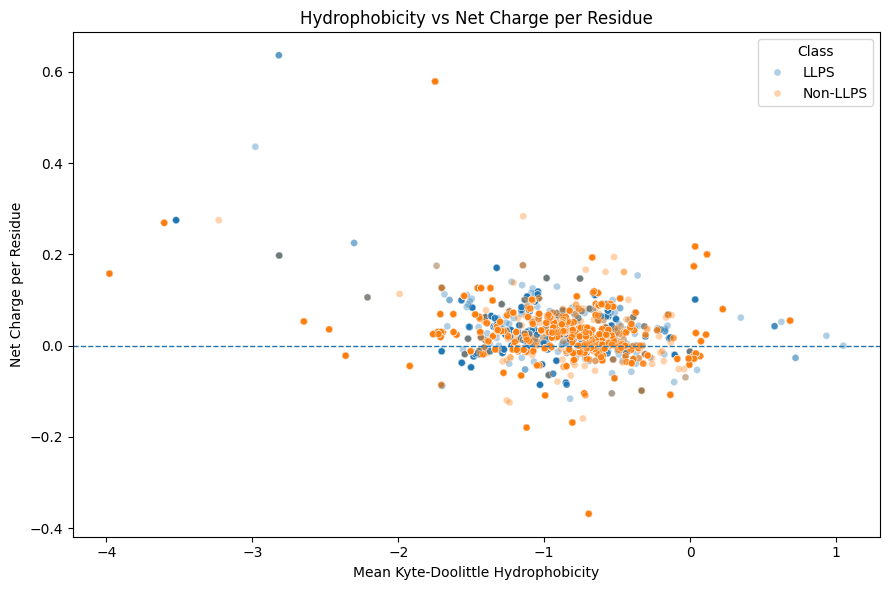

In [ ]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=df,
    x='Mean_KD_hydrophobicity',
    y='Net_charge_per_residue',
    hue='Class',
    alpha=0.35,
    s=25
)

plt.title('Hydrophobicity vs Net Charge per Residue')
plt.xlabel('Mean Kyte-Doolittle Hydrophobicity')
plt.ylabel('Net Charge per Residue')
plt.axhline(0, linestyle='--', linewidth=1)
plt.tight_layout()
plt.show()

In [ ]:
pearson_corr = df['Mean_KD_hydrophobicity'].corr(
    df['Net_charge_per_residue'],
    method='pearson'
)

spearman_corr = df['Mean_KD_hydrophobicity'].corr(
    df['Net_charge_per_residue'],
    method='spearman'
)

print(f"Pearson correlation:  {pearson_corr:.4f}")
print(f"Spearman correlation: {spearman_corr:.4f}")

Pearson correlation:  -0.0922
Spearman correlation: -0.0338


In [ ]:
for label in [1, 0]:

    subset = df[df['Label'] == label]

    pearson = subset['Mean_KD_hydrophobicity'].corr(
        subset['Net_charge_per_residue'],
        method='pearson'
    )

    spearman = subset['Mean_KD_hydrophobicity'].corr(
        subset['Net_charge_per_residue'],
        method='spearman'
    )

    name = 'LLPS' if label == 1 else 'Non-LLPS'

    print(f'{name}:')
    print(f'  Pearson  = {pearson:.4f}')
    print(f'  Spearman = {spearman:.4f}')

LLPS:
  Pearson  = -0.2891
  Spearman = 0.0089
Non-LLPS:
  Pearson  = 0.0935
  Spearman = -0.0409


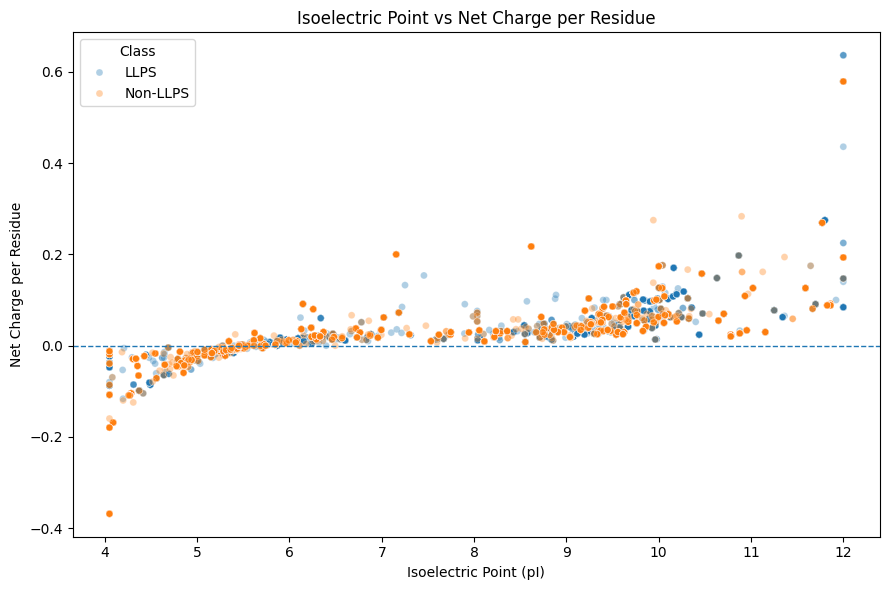

In [ ]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=df,
    x='pI',
    y='Net_charge_per_residue',
    hue='Class',
    alpha=0.35,
    s=25
)

plt.title('Isoelectric Point vs Net Charge per Residue')
plt.xlabel('Isoelectric Point (pI)')
plt.ylabel('Net Charge per Residue')
plt.axhline(0, linestyle='--', linewidth=1)
plt.tight_layout()
plt.show()

In [ ]:
pearson_corr = df['pI'].corr(
    df['Net_charge_per_residue'],
    method='pearson'
)

spearman_corr = df['pI'].corr(
    df['Net_charge_per_residue'],
    method='spearman'
)

print(f"Pearson correlation:  {pearson_corr:.4f}")
print(f"Spearman correlation: {spearman_corr:.4f}")

Pearson correlation:  0.6141
Spearman correlation: 0.7372


In [ ]:
for label in [1, 0]:

    subset = df[df['Label'] == label]

    pearson = subset['pI'].corr(
        subset['Net_charge_per_residue'],
        method='pearson'
    )

    spearman = subset['pI'].corr(
        subset['Net_charge_per_residue'],
        method='spearman'
    )

    name = 'LLPS' if label == 1 else 'Non-LLPS'

    print(f'{name}:')
    print(f'  Pearson  = {pearson:.4f}')
    print(f'  Spearman = {spearman:.4f}')

LLPS:
  Pearson  = 0.6905
  Spearman = 0.7661
Non-LLPS:
  Pearson  = 0.5520
  Spearman = 0.7268


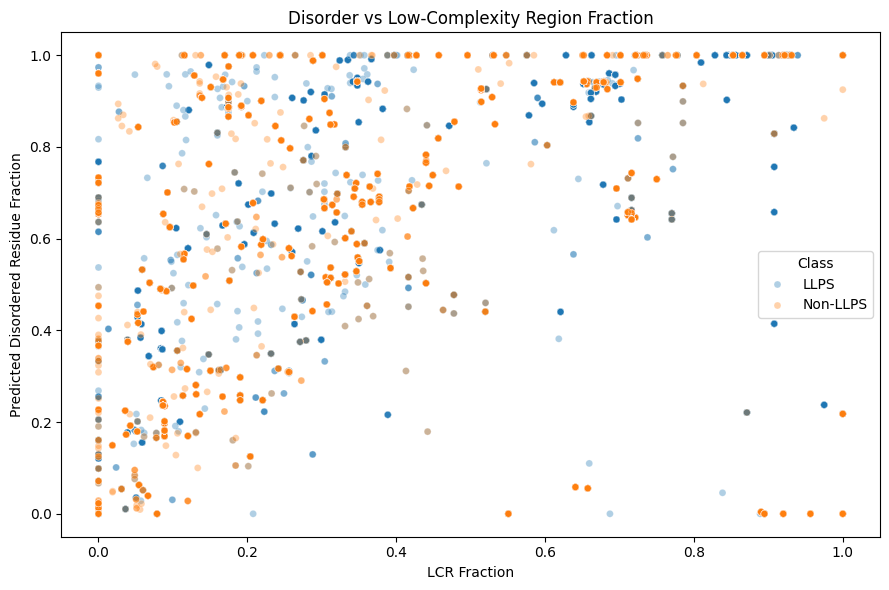

In [ ]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=df,
    x='LCR_frac',
    y='IUPred3_disordered_frac',
    hue='Class',
    alpha=0.35,
    s=25
)

plt.title('Disorder vs Low-Complexity Region Fraction')
plt.xlabel('LCR Fraction')
plt.ylabel('Predicted Disordered Residue Fraction')
plt.tight_layout()
plt.show()

In [ ]:
pearson_corr = df['LCR_frac'].corr(
    df['IUPred3_disordered_frac'],
    method='pearson'
)

spearman_corr = df['LCR_frac'].corr(
    df['IUPred3_disordered_frac'],
    method='spearman'
)

print(f"Pearson correlation:  {pearson_corr:.4f}")
print(f"Spearman correlation: {spearman_corr:.4f}")

Pearson correlation:  0.1633
Spearman correlation: 0.3163


In [ ]:
for label in [1, 0]:

    subset = df[df['Label'] == label]

    pearson = subset['LCR_frac'].corr(
        subset['IUPred3_disordered_frac'],
        method='pearson'
    )

    spearman = subset['LCR_frac'].corr(
        subset['IUPred3_disordered_frac'],
        method='spearman'
    )

    name = 'LLPS' if label == 1 else 'Non-LLPS'

    print(f'{name}:')
    print(f'  Pearson  = {pearson:.4f}')
    print(f'  Spearman = {spearman:.4f}')

LLPS:
  Pearson  = 0.3806
  Spearman = 0.4886
Non-LLPS:
  Pearson  = -0.0719
  Spearman = 0.0888


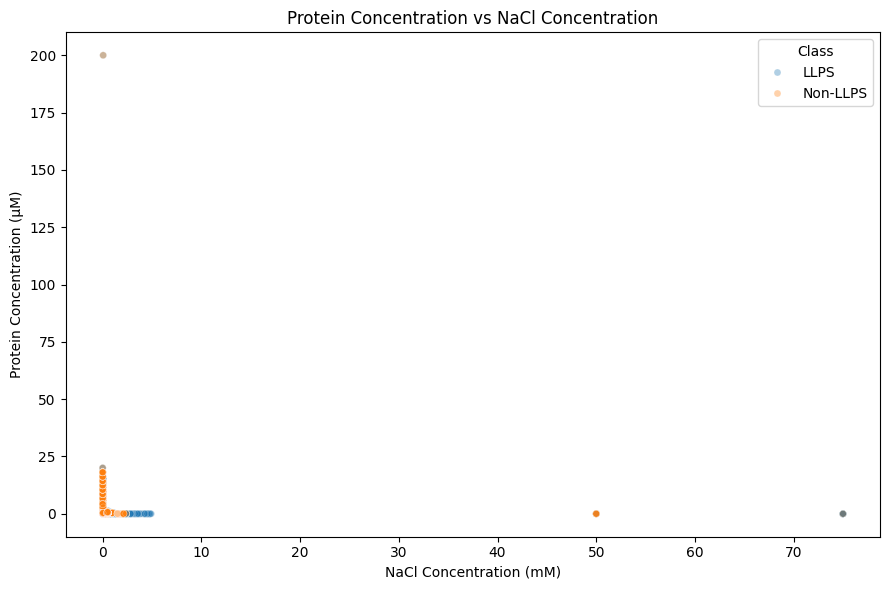

In [ ]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=df,
    x='NaCl_mM',
    y='protein_conc_uM',
    hue='Class',
    alpha=0.35,
    s=25
)

plt.title('Protein Concentration vs NaCl Concentration')
plt.xlabel('NaCl Concentration (mM)')
plt.ylabel('Protein Concentration (µM)')
plt.tight_layout()
plt.show()

In [ ]:
pearson_corr = df['NaCl_mM'].corr(
    df['protein_conc_uM'],
    method='pearson'
)

spearman_corr = df['NaCl_mM'].corr(
    df['protein_conc_uM'],
    method='spearman'
)

print(f"Pearson correlation:  {pearson_corr:.4f}")
print(f"Spearman correlation: {spearman_corr:.4f}")

Pearson correlation:  -0.0067
Spearman correlation: 0.0508


In [ ]:
for label in [1, 0]:

    subset = df[df['Label'] == label]

    pearson = subset['NaCl_mM'].corr(
        subset['protein_conc_uM'],
        method='pearson'
    )

    spearman = subset['NaCl_mM'].corr(
        subset['protein_conc_uM'],
        method='spearman'
    )

    name = 'LLPS' if label == 1 else 'Non-LLPS'

    print(f'{name}:')
    print(f'  Pearson  = {pearson:.4f}')
    print(f'  Spearman = {spearman:.4f}')

LLPS:
  Pearson  = -0.0035
  Spearman = 0.0655
Non-LLPS:
  Pearson  = -0.0127
  Spearman = 0.0096


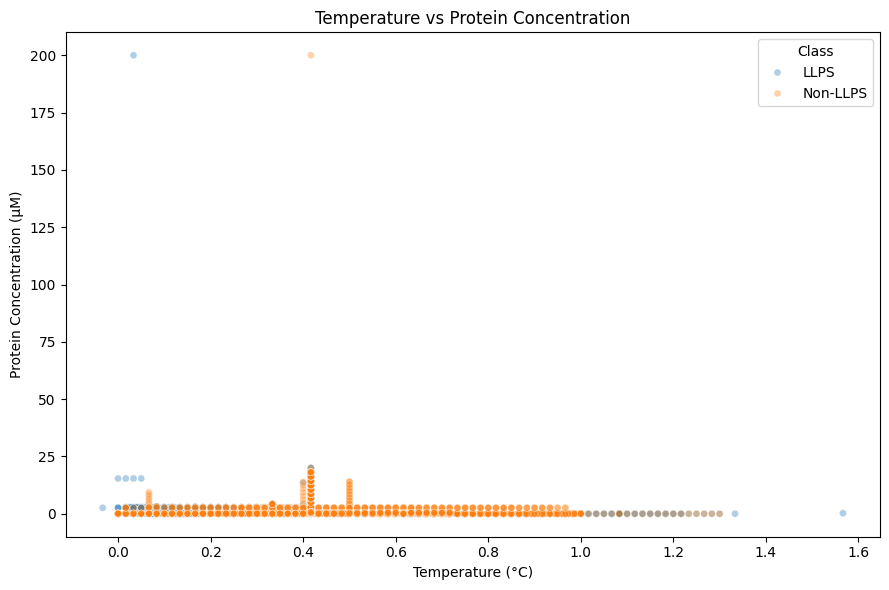

In [ ]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=df,
    x='temperature_C',
    y='protein_conc_uM',
    hue='Class',
    alpha=0.35,
    s=25
)

plt.title('Temperature vs Protein Concentration')
plt.xlabel('Temperature (°C)')
plt.ylabel('Protein Concentration (µM)')
plt.tight_layout()
plt.show()

In [ ]:
pearson_corr = df['temperature_C'].corr(
    df['protein_conc_uM'],
    method='pearson'
)

spearman_corr = df['temperature_C'].corr(
    df['protein_conc_uM'],
    method='spearman'
)

print(f"Pearson correlation:  {pearson_corr:.4f}")
print(f"Spearman correlation: {spearman_corr:.4f}")

Pearson correlation:  -0.0286
Spearman correlation: -0.0244


In [ ]:
for label in [1, 0]:

    subset = df[df['Label'] == label]

    pearson = subset['temperature_C'].corr(
        subset['protein_conc_uM'],
        method='pearson'
    )

    spearman = subset['temperature_C'].corr(
        subset['protein_conc_uM'],
        method='spearman'
    )

    name = 'LLPS' if label == 1 else 'Non-LLPS'

    print(f'{name}:')
    print(f'  Pearson  = {pearson:.4f}')
    print(f'  Spearman = {spearman:.4f}')

LLPS:
  Pearson  = -0.0565
  Spearman = 0.0716
Non-LLPS:
  Pearson  = -0.0098
  Spearman = -0.1660


In [ ]:
corr_features = [
    'Sequence_length',
    'Molecular_weight',
    'pI',
    'Mean_KD_hydrophobicity',
    'Shannon_entropy',
    'Net_charge_per_residue',
    'Positive_charge_frac',
    'Negative_charge_frac',
    'Polar_frac',
    'Arom_frac',
    'AA_P_frac',
    'AA_G_frac',
    'IUPred3_mean',
    'IUPred3_disordered_frac',
    'LCR_frac',
    'temperature_C',
    'protein_conc_uM',
    'NaCl_mM',
    'KCl_mM',
    'MgCl2_mM'
]

corr_matrix = df[corr_features].corr(method='spearman')

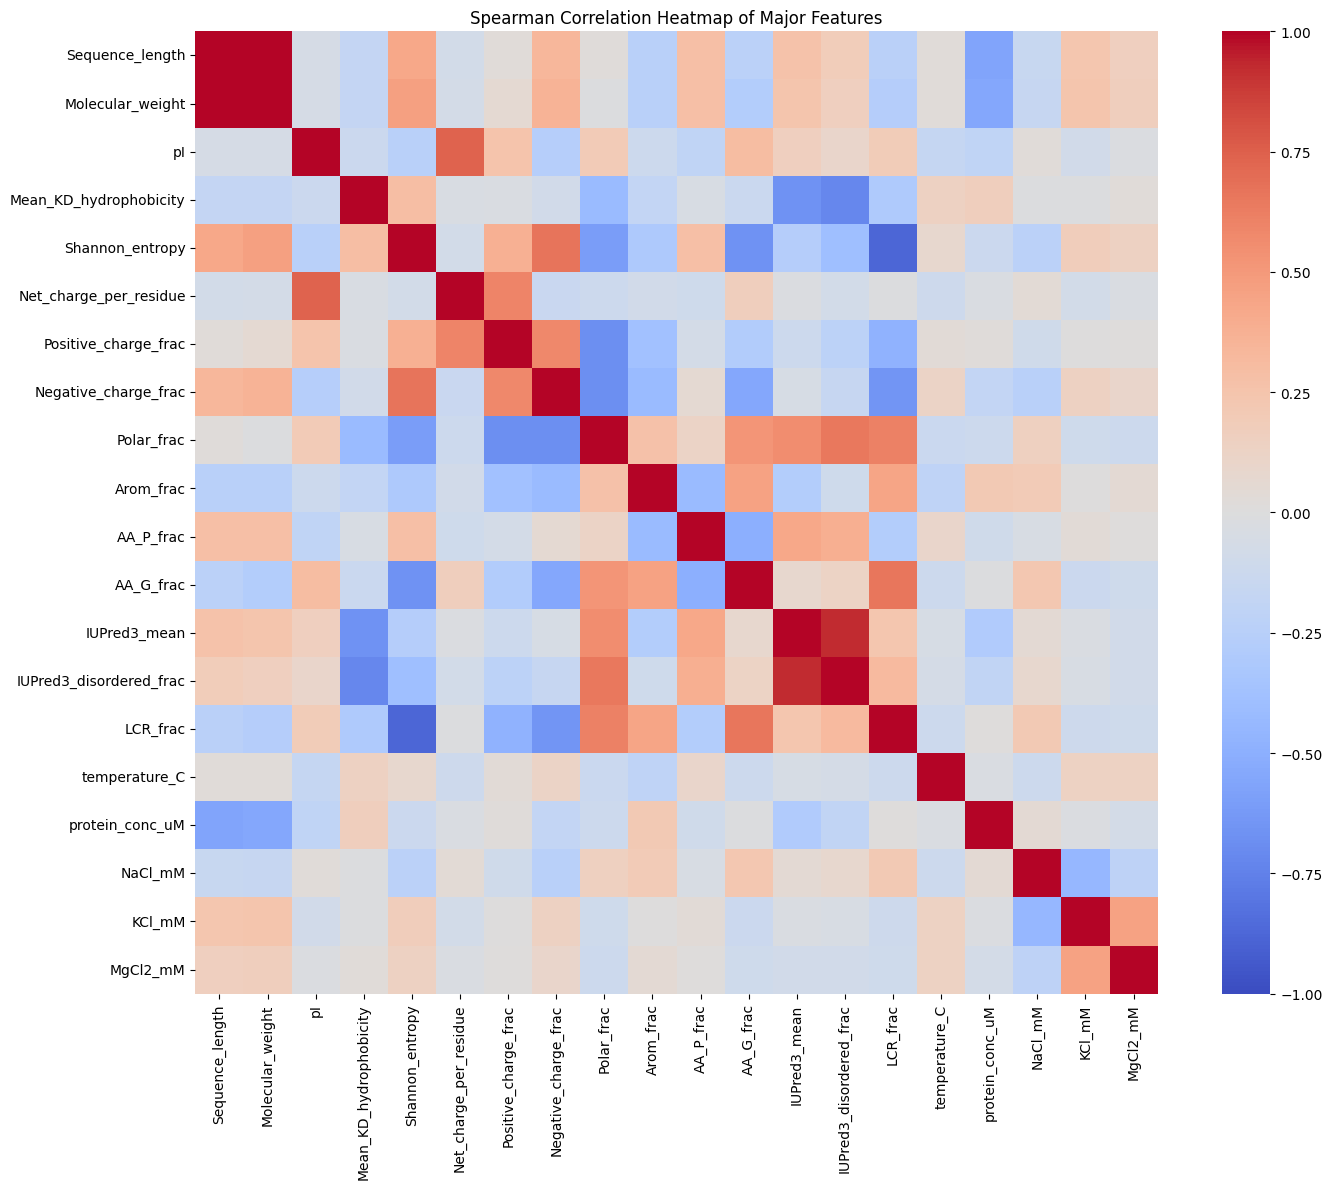

In [ ]:
plt.figure(figsize=(15, 12))

sns.heatmap(
    corr_matrix,
    cmap='coolwarm',
    center=0,
    vmin=-1,
    vmax=1,
    square=True
)

plt.title('Spearman Correlation Heatmap of Major Features')
plt.tight_layout()
plt.show()

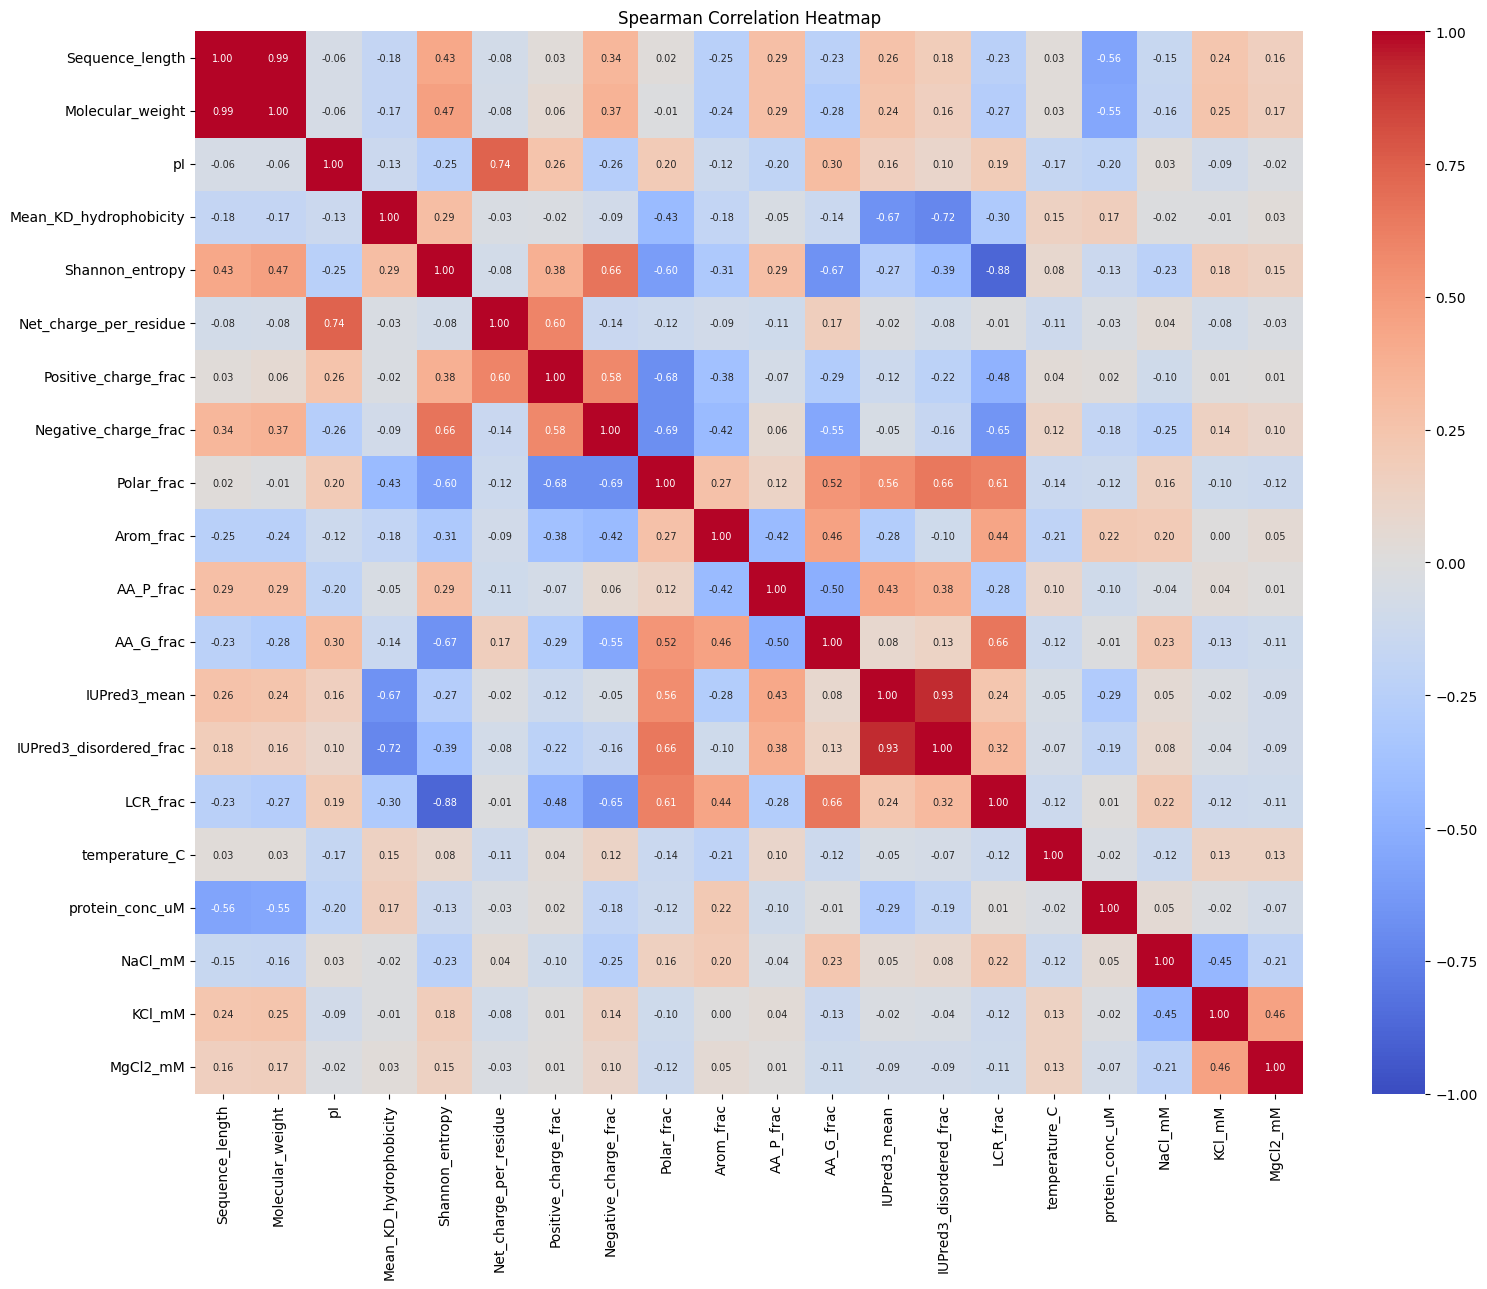

In [ ]:
plt.figure(figsize=(16, 13))

sns.heatmap(
    corr_matrix,
    cmap='coolwarm',
    center=0,
    vmin=-1,
    vmax=1,
    annot=True,
    fmt='.2f',
    annot_kws={'size': 7}
)

plt.title('Spearman Correlation Heatmap')
plt.tight_layout()
plt.show()

In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

pca_features = [
    'Sequence_length',
    'Molecular_weight',
    'pI',
    'Mean_KD_hydrophobicity',
    'Shannon_entropy',
    'Net_charge_per_residue',
    'Positive_charge_frac',
    'Negative_charge_frac',
    'Polar_frac',
    'Arom_frac',
    'AA_P_frac',
    'AA_G_frac',
    'IUPred3_mean',
    'IUPred3_disordered_frac',
    'LCR_frac',
    'temperature_C',
    'protein_conc_uM',
    'NaCl_mM',
    'KCl_mM',
    'MgCl2_mM'
]

X_pca = df[pca_features]

# Standardize features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_pca)

print("Original shape:", X_pca.shape)
print("Scaled shape:", X_scaled.shape)

Original shape: (20719, 20)
Scaled shape: (20719, 20)


In [ ]:
pca = PCA()

X_pca_result = pca.fit_transform(X_scaled)

explained_variance = pca.explained_variance_ratio_

print("Explained variance by each PC:")
for i, var in enumerate(explained_variance[:10], 1):
    print(f"PC{i}: {var:.4f} ({var*100:.2f}%)")

print(
    f"\nPC1 + PC2 explain "
    f"{(explained_variance[0] + explained_variance[1])*100:.2f}% of variance"
)

Explained variance by each PC:
PC1: 0.2252 (22.52%)
PC2: 0.1682 (16.82%)
PC3: 0.1213 (12.13%)
PC4: 0.0773 (7.73%)
PC5: 0.0661 (6.61%)
PC6: 0.0540 (5.40%)
PC7: 0.0497 (4.97%)
PC8: 0.0495 (4.95%)
PC9: 0.0484 (4.84%)
PC10: 0.0424 (4.24%)

PC1 + PC2 explain 39.34% of variance


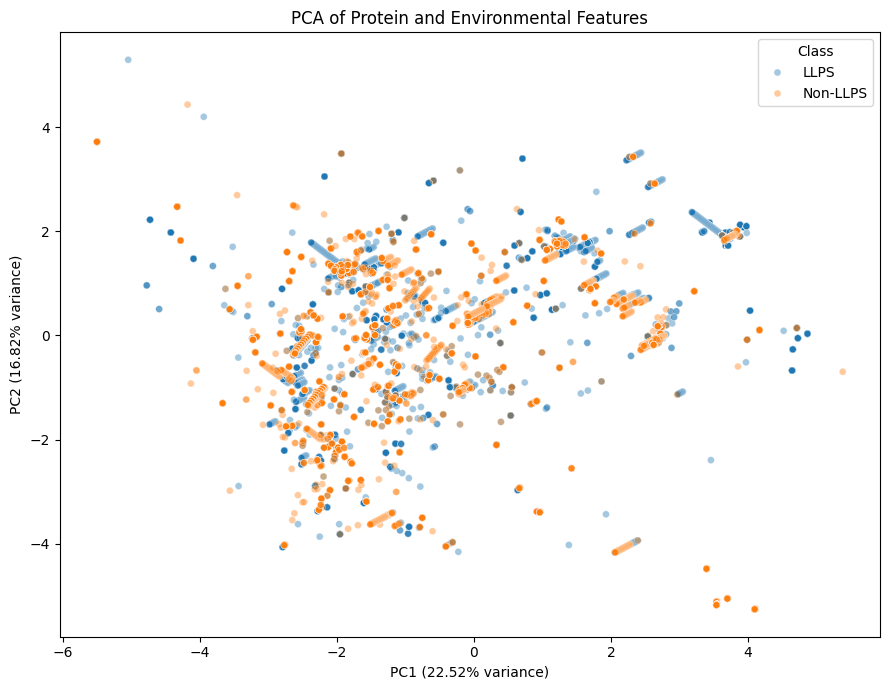

In [ ]:
plt.figure(figsize=(9, 7))

sns.scatterplot(
    x=X_pca_result[:, 0],
    y=X_pca_result[:, 1],
    hue=df['Class'],
    alpha=0.4,
    s=25
)

plt.xlabel(
    f'PC1 ({explained_variance[0]*100:.2f}% variance)'
)

plt.ylabel(
    f'PC2 ({explained_variance[1]*100:.2f}% variance)'
)

plt.title('PCA of Protein and Environmental Features')
plt.tight_layout()
plt.show()

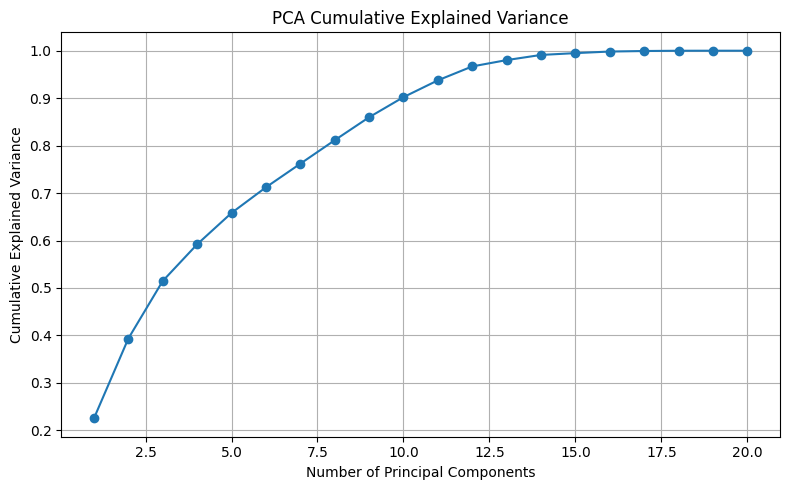

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(
    range(1, len(explained_variance) + 1),
    np.cumsum(explained_variance),
    marker='o'
)

plt.xlabel('Number of Principal Components')
plt.ylabel('Cumulative Explained Variance')
plt.title('PCA Cumulative Explained Variance')
plt.grid(True)

plt.tight_layout()
plt.show()

In [ ]:
# PCA loadings
loadings = pd.DataFrame(
    pca.components_.T,
    index=pca_features,
    columns=[f'PC{i}' for i in range(1, len(pca_features) + 1)]
)

# PC1 loadings
print("PC1 loadings:")
print(
    loadings['PC1']
    .sort_values(key=abs, ascending=False)
    .round(4)
)

print("\nPC2 loadings:")
print(
    loadings['PC2']
    .sort_values(key=abs, ascending=False)
    .round(4)
)

PC1 loadings:
LCR_frac                   0.4087
Shannon_entropy           -0.3880
AA_G_frac                  0.3636
Negative_charge_frac      -0.3635
Polar_frac                 0.3461
Arom_frac                  0.2994
Molecular_weight          -0.2447
Positive_charge_frac      -0.2438
Sequence_length           -0.2270
AA_P_frac                 -0.1278
pI                         0.0794
IUPred3_disordered_frac    0.0635
Net_charge_per_residue     0.0510
temperature_C             -0.0494
Mean_KD_hydrophobicity    -0.0491
KCl_mM                    -0.0444
protein_conc_uM           -0.0313
MgCl2_mM                  -0.0218
NaCl_mM                   -0.0110
IUPred3_mean               0.0087
Name: PC1, dtype: float64

PC2 loadings:
IUPred3_mean               0.5002
IUPred3_disordered_frac    0.4968
Polar_frac                 0.3292
AA_P_frac                  0.3038
Sequence_length            0.2634
Mean_KD_hydrophobicity    -0.2594
Molecular_weight           0.2512
Net_charge_per_residue    -

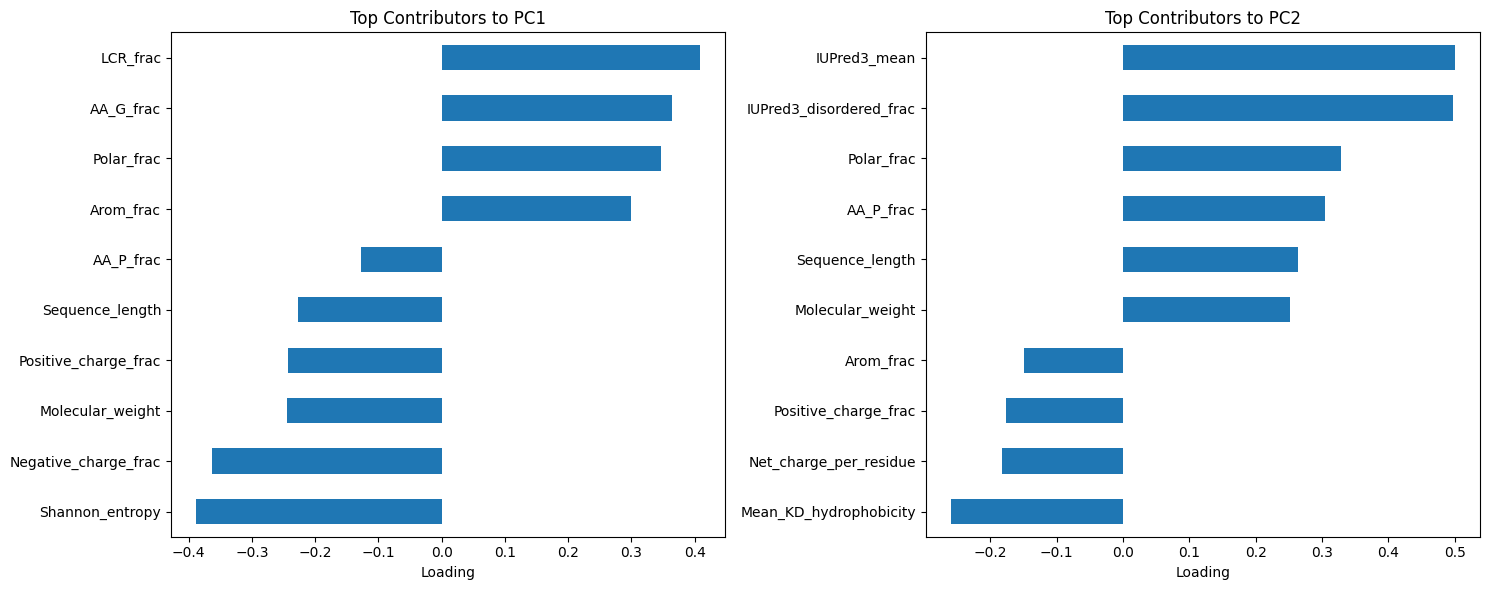

In [ ]:
# Top 10 contributors to PC1 and PC2

pc1_top = loadings['PC1'].sort_values(
    key=abs, ascending=False
).head(10)

pc2_top = loadings['PC2'].sort_values(
    key=abs, ascending=False
).head(10)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

pc1_top.sort_values().plot(
    kind='barh',
    ax=axes[0]
)

axes[0].set_title('Top Contributors to PC1')
axes[0].set_xlabel('Loading')

pc2_top.sort_values().plot(
    kind='barh',
    ax=axes[1]
)

axes[1].set_title('Top Contributors to PC2')
axes[1].set_xlabel('Loading')

plt.tight_layout()
plt.show()


In [ ]:
from scipy.stats import mannwhitneyu

analysis_features = [
    'Sequence_length',
    'Molecular_weight',
    'pI',
    'Mean_KD_hydrophobicity',
    'Shannon_entropy',
    'Net_charge_per_residue',
    'Positive_charge_frac',
    'Negative_charge_frac',
    'Polar_frac',
    'Arom_frac',
    'AA_P_frac',
    'AA_G_frac',
    'IUPred3_mean',
    'IUPred3_disordered_frac',
    'LCR_frac'
]

results = []

llps = df[df['Label'] == 1]
non_llps = df[df['Label'] == 0]

for feature in analysis_features:

    x = llps[feature]
    y = non_llps[feature]

    # Mann-Whitney U
    u_stat, p_value = mannwhitneyu(
        x, y,
        alternative='two-sided'
    )

    # Rank-biserial effect size
    n1 = len(x)
    n2 = len(y)

    rank_biserial = (2 * u_stat) / (n1 * n2) - 1

    # AUC
    auc = u_stat / (n1 * n2)

    results.append([
        feature,
        x.median(),
        y.median(),
        p_value,
        rank_biserial,
        auc
    ])

results_df = pd.DataFrame(
    results,
    columns=[
        'Feature',
        'LLPS_Median',
        'NonLLPS_Median',
        'P_Value',
        'Rank_Biserial',
        'AUC'
    ]
)

results_df = results_df.sort_values(
    'AUC',
    ascending=False
)

print(results_df.to_string(index=False))

                Feature  LLPS_Median  NonLLPS_Median       P_Value  Rank_Biserial      AUC
             Polar_frac     0.483146        0.456483 4.078885e-163       0.220033 0.610016
IUPred3_disordered_frac     0.828947        0.657718 5.426402e-159       0.216608 0.608304
           IUPred3_mean     0.655532        0.621306 2.241188e-144       0.206858 0.603429
        Sequence_length   316.000000      202.000000 4.197561e-109       0.179362 0.589681
       Molecular_weight 33968.786500    21464.416100  1.018878e-96       0.168730 0.584365
              AA_P_frac     0.061538        0.051331  1.579779e-59       0.131523 0.565762
               LCR_frac     0.357447        0.322581  1.384105e-33       0.097588 0.548794
                     pI     9.035196        7.943617  3.637634e-31       0.093855 0.546928
 Net_charge_per_residue     0.029412        0.026846  9.582286e-04       0.026697 0.513348
              AA_G_frac     0.130769        0.130769  5.835487e-01       0.004432 0.502216

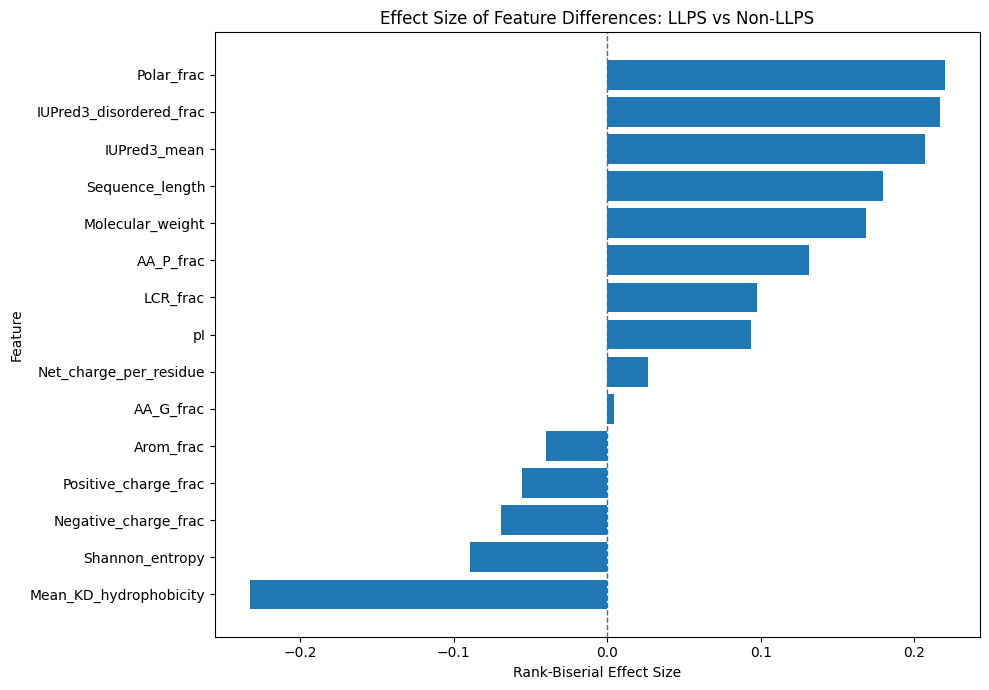

In [ ]:
plt.figure(figsize=(10, 7))

plot_df = results_df.sort_values(
    'Rank_Biserial'
)

plt.barh(
    plot_df['Feature'],
    plot_df['Rank_Biserial']
)

plt.axvline(0, linestyle='--', linewidth=1)

plt.xlabel('Rank-Biserial Effect Size')
plt.ylabel('Feature')
plt.title('Effect Size of Feature Differences: LLPS vs Non-LLPS')

plt.tight_layout()
plt.show()

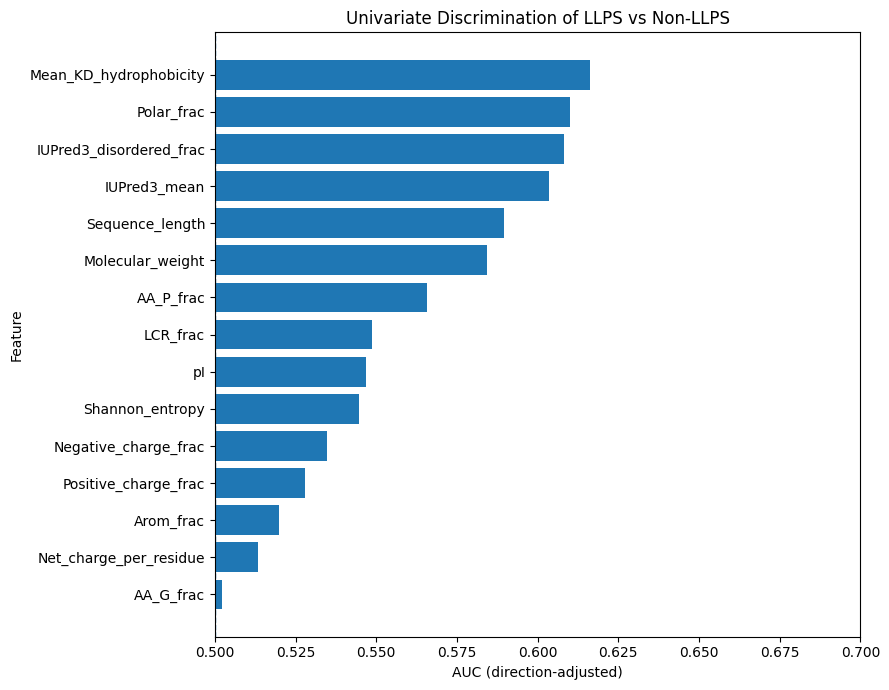

In [ ]:
auc_plot = results_df.copy()

# Convert AUC below 0.5 so that larger values always mean
# stronger separation, regardless of direction.
auc_plot['AUC_strength'] = auc_plot['AUC'].apply(
    lambda x: max(x, 1 - x)
)

auc_plot = auc_plot.sort_values('AUC_strength')

plt.figure(figsize=(9, 7))

plt.barh(
    auc_plot['Feature'],
    auc_plot['AUC_strength']
)

plt.axvline(
    0.5,
    linestyle='--',
    linewidth=1
)

plt.xlabel('AUC (direction-adjusted)')
plt.ylabel('Feature')
plt.title('Univariate Discrimination of LLPS vs Non-LLPS')
plt.xlim(0.5, 0.7)

plt.tight_layout()
plt.show()